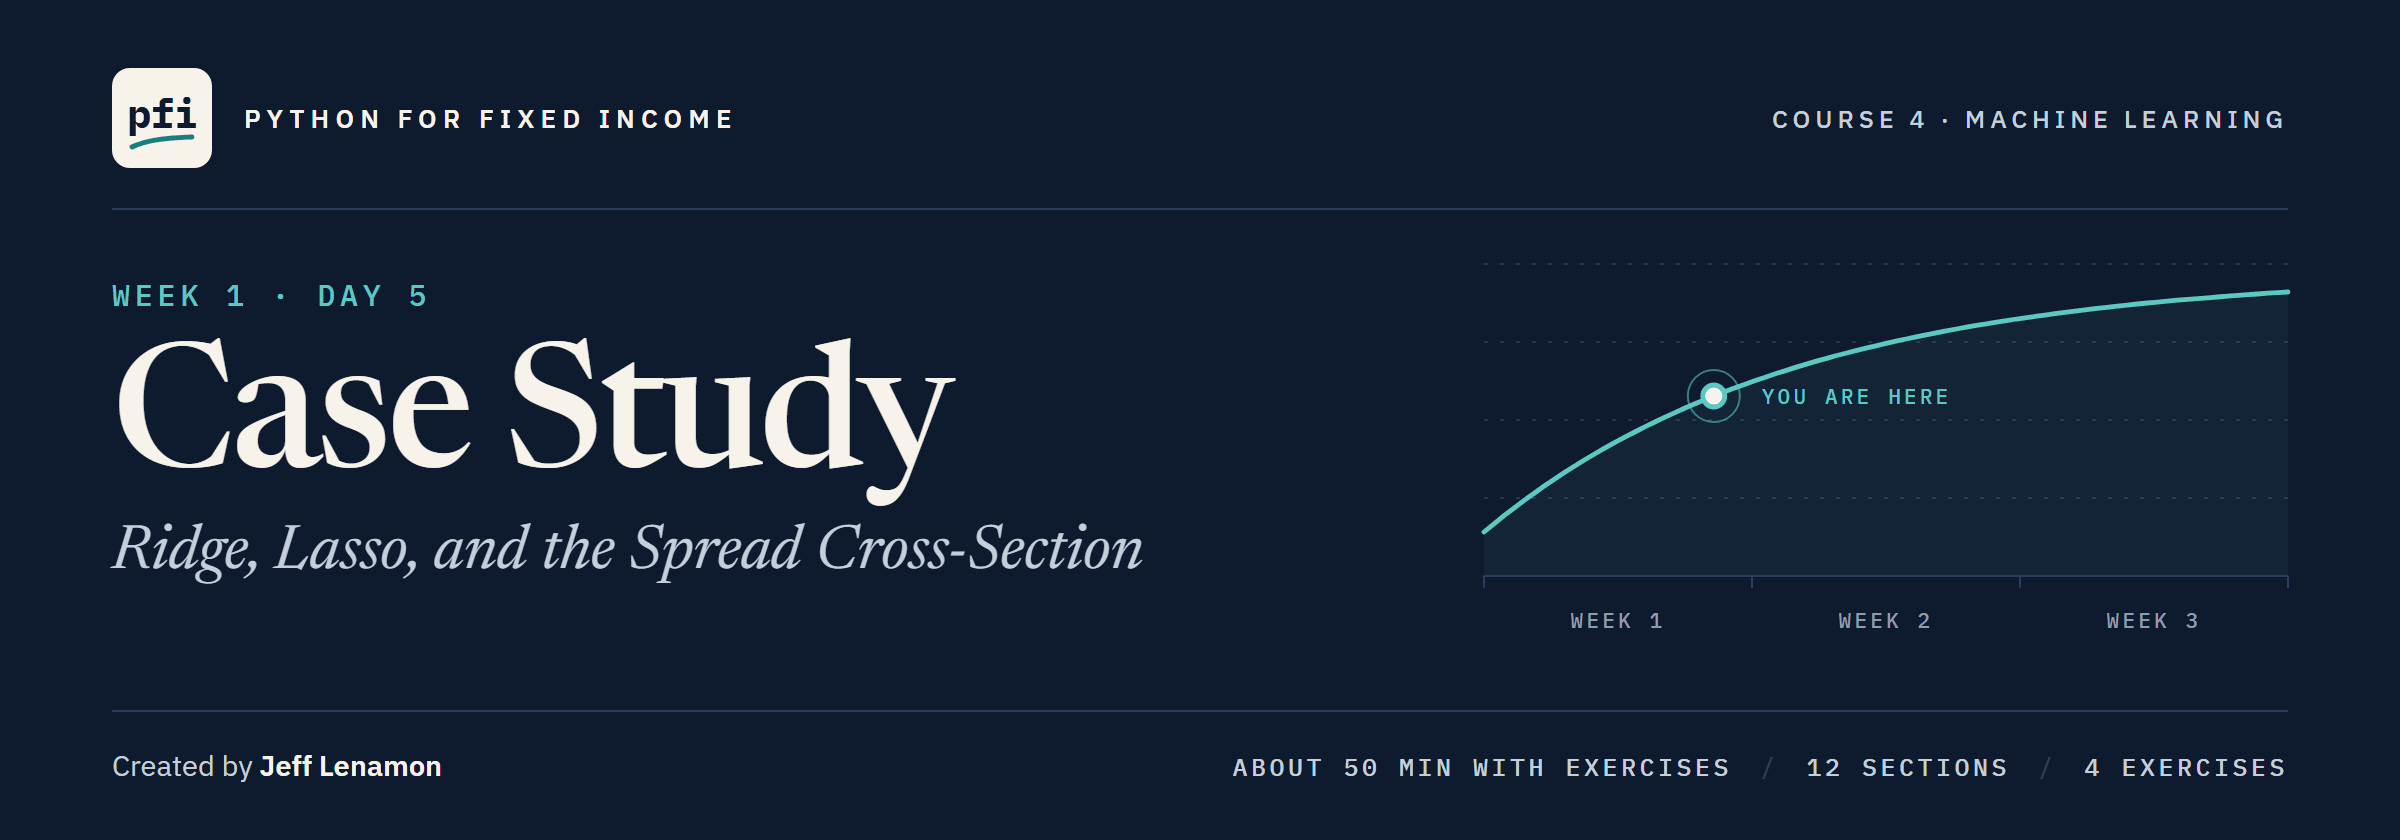

# Case Study: Ridge, Lasso, and the Spread Cross-Section

Week 1, Day 5. Put every column of the file into one pipeline, let ridge and lasso price the coefficients, choose the penalty by cross-validation, and score a new issuer honestly.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day5/05_case_study_ridge_lasso_and_the_spread_cross_section.ipynb)

# Problem Statement

## Business Context

Day 4's log model misses a typical unseen bond by 33.1 bp, using only the rating and years to maturity.
The credit team asks to add every other column the file holds, sector, duration, coupon, amount and issuer, and let a penalty sort out which earn their place.
It wants two misses reported honestly: on a new bond of a known issuer, and on a bond of an issuer never seen.
The bonds and issuers are invented for this course, and every number below describes them, never a view on one.

## Objectives

Build one pipeline that prepares every column on the training bonds only.
Fit least squares, ridge and lasso on the same 30 columns, each penalty chosen by cross-validation, read the columns lasso keeps against the recipe, and score issuers the model has never seen.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `issuer` and `ticker`: the issuer's name and short code
3. `sector`: one of 10 industry sectors
4. `rating`: credit rating, AAA to CCC
5. `coupon`: annual coupon, percent of par
6. `maturity` and `as_of_date`: dates; years to maturity is built from them
7. `oas`: option-adjusted spread, bp; **the target is its log**
8. `duration`: modified duration, years
9. `amount_outstanding`: face value outstanding, dollars

The file's other columns are not used today.

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC) and `grade`.

## Your Route Through Day 5

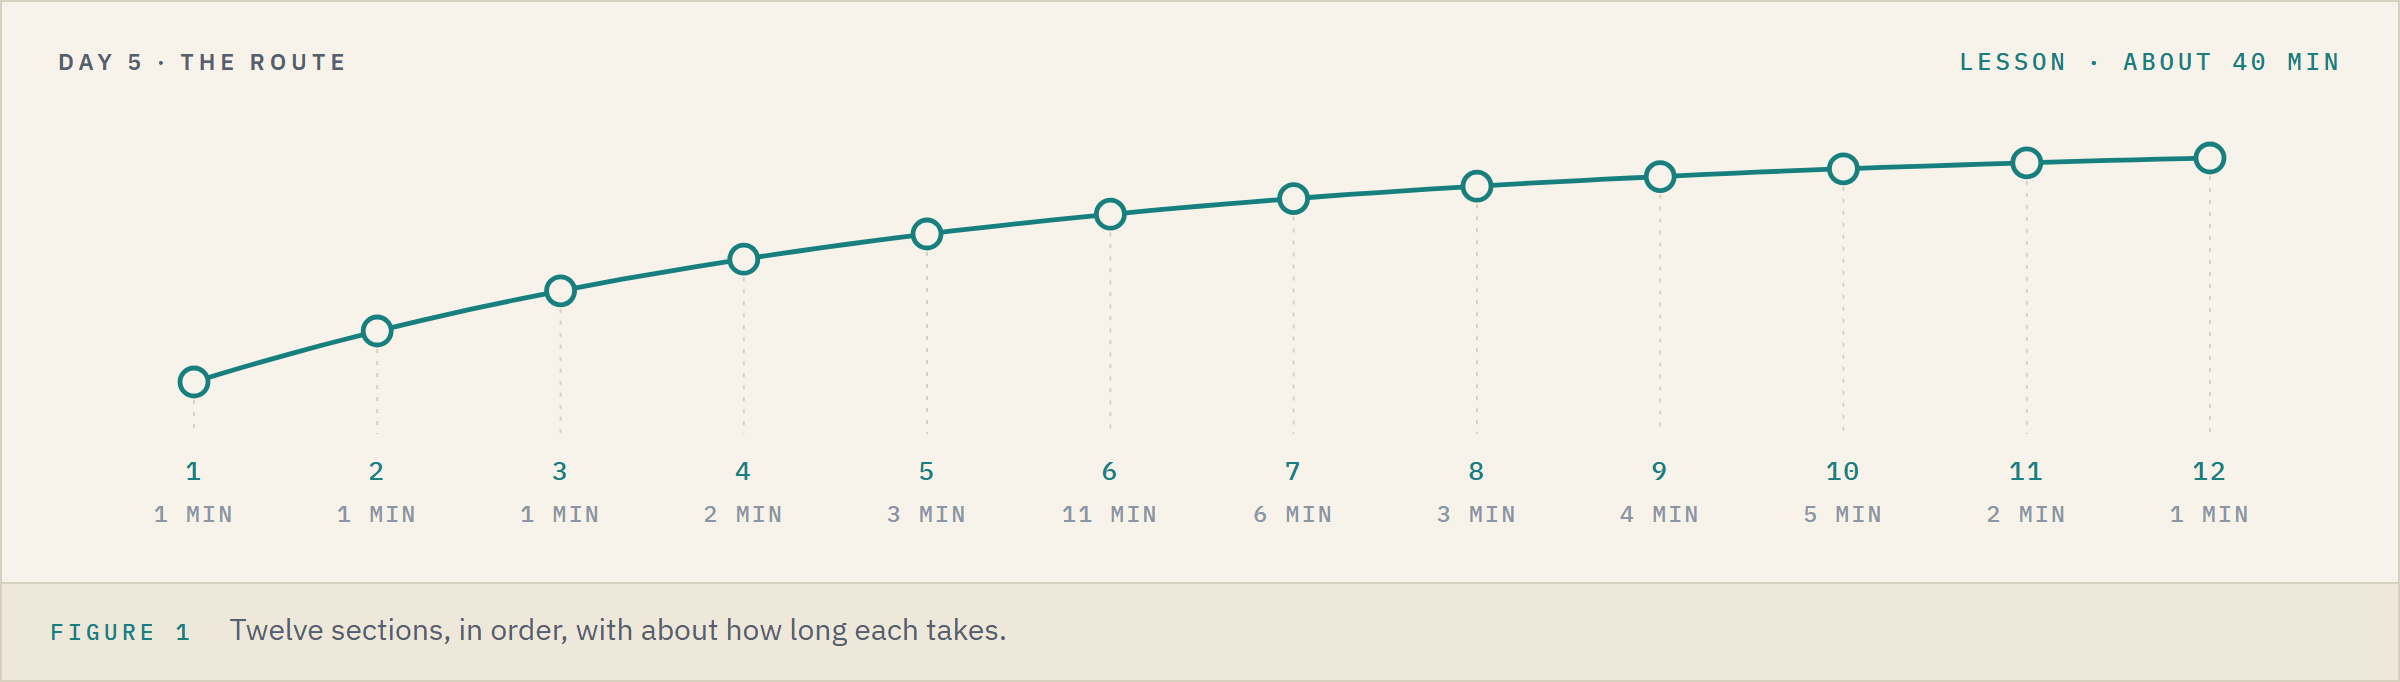

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">1 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">2 min</td></tr>
<tr><td align="left">5</td><td align="left">Data Preparation for Modeling</td><td align="left">3 min</td></tr>
<tr><td align="left">6</td><td align="left">Model Building</td><td align="left">11 min</td></tr>
<tr><td align="left">7</td><td align="left">Choosing Alpha</td><td align="left">6 min</td></tr>
<tr><td align="left">8</td><td align="left">Model Performance Evaluation</td><td align="left">3 min</td></tr>
<tr><td align="left">9</td><td align="left">Reading the Coefficients</td><td align="left">4 min</td></tr>
<tr><td align="left">10</td><td align="left">The Split by Issuer</td><td align="left">5 min</td></tr>
<tr><td align="left">11</td><td align="left">Where the Model Fails</td><td align="left">2 min</td></tr>
<tr><td align="left">12</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 40 minutes for the lesson, then about 12 for the four exercises.

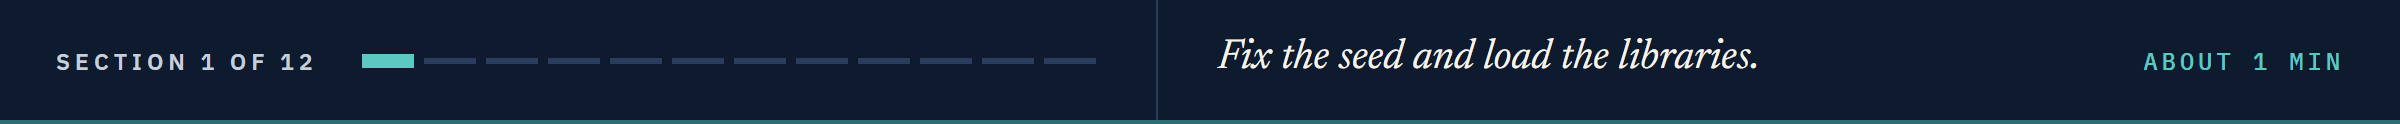

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# to split the bonds, fold the training bonds, and score on the folds
from sklearn.model_selection import train_test_split, KFold, GroupKFold, GroupShuffleSplit
from sklearn.model_selection import cross_val_score, cross_validate

# the steps of a pipeline, and the models
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV

# to measure misses in bp
from sklearn.metrics import mean_absolute_error, mean_squared_error, make_scorer

# one look for every chart, and plain numbers with three decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

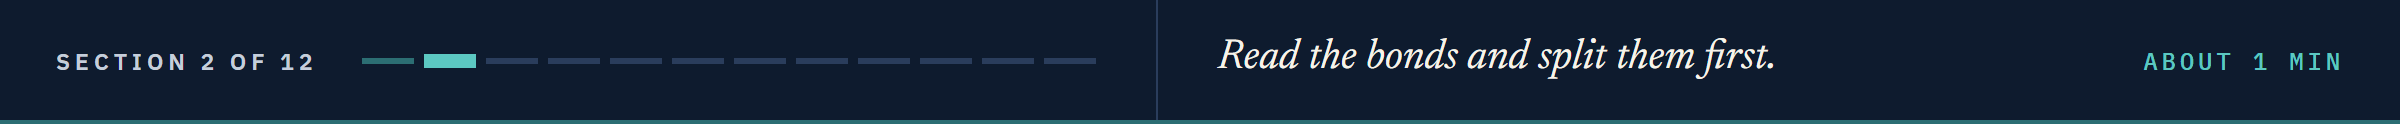

# Loading the Data

## Reading the Bonds and Building Three Columns

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")
rating_order = list(ratings["rating"])

# years to maturity (Day 3's line), the amount in billions, and the target: the log of OAS (Day 4)
data["years_to_maturity"] = (pd.to_datetime(data["maturity"]) - pd.to_datetime(data["as_of_date"])).dt.days / 365.25
data["amount_bn"] = data["amount_outstanding"] / 1e9
data["log_oas"] = np.log(data["oas"])

## Splitting the Bonds First

In [4]:
# the course split, with the seed: the same 615 and 206 bonds as Days 1 to 4
train, test = train_test_split(data, test_size=0.25, random_state=SEED)
print("Training bonds:", len(train), " Test bonds:", len(test))

Training bonds: 615  Test bonds: 206


The split comes first today, so the overview and the exploration read training bonds only.

**From here the test bonds only score a fitted model; nothing is chosen on them.**

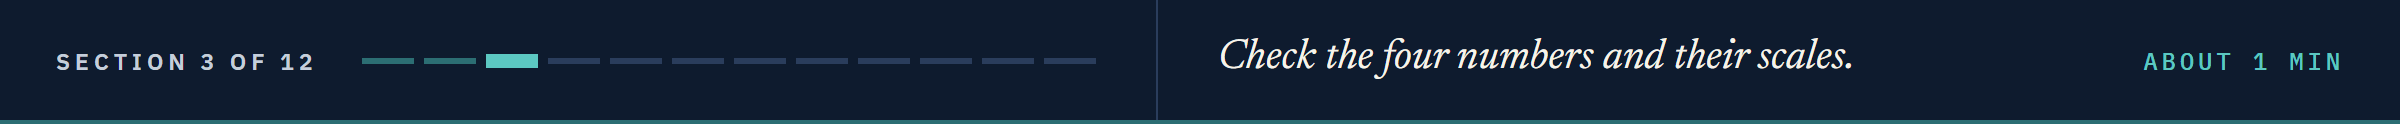

# Data Overview

## The Candidate Columns

In [5]:
# the four numbers today's models may use, and the columns around them
NUMBERS = ["years_to_maturity", "duration", "coupon", "amount_bn"]
train[["ticker", "rating", "sector"] + NUMBERS + ["log_oas"]].head()

,ticker,rating,sector,years_to_maturity,duration,coupon,amount_bn,log_oas
712,ELVX,A+,Telecom,4.567,4.130,3.125,0.950,3.892
181,HESN,A+,Industrials,19.803,13.456,3.250,1.600,4.078
778,PLEA,AA,Financials,2.538,2.371,3.250,1.150,3.091
716,PLER,BBB-,Energy,3.422,3.040,6.000,2.300,5.380
636,GROR,BBB+,Financials,19.264,11.478,5.500,2.250,4.852


## Their Scales

In [6]:
# the four numbers on the training bonds
train[NUMBERS].describe()

,years_to_maturity,duration,coupon,amount_bn
count,615.000,615.000,615.000,615.000
mean,8.763,5.918,5.873,1.394
std,6.792,3.224,1.698,0.657
min,0.964,0.915,1.500,0.300
25%,4.030,3.454,4.750,0.850
50%,7.587,5.882,5.625,1.350
75%,10.661,7.649,6.812,1.950
max,29.897,15.130,11.000,2.500


Two text columns, an issuer code, and four numbers on four scales: years run from 0.96 to 29.9 (standard deviation 6.79), the amount from 0.30 to 2.50 billion (0.66).

A coefficient's size depends on its column's unit.

**First, what earlier days already know.**

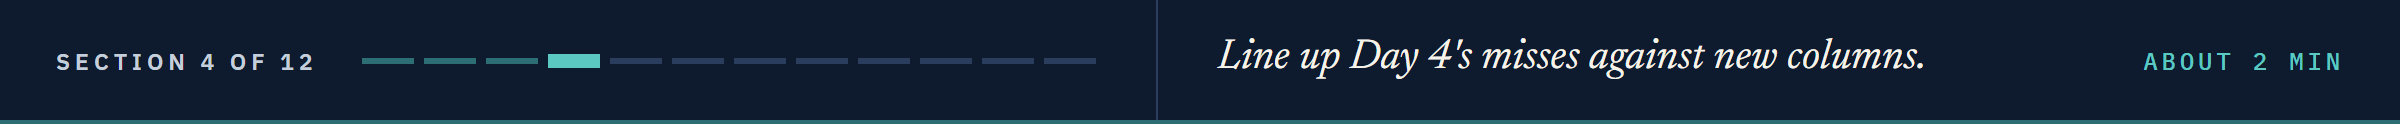

# Exploratory Data Analysis

## What Days 1 to 4 Found

Four days of findings:

* OAS has a long right tail, so the target is its log (Day 4).
* Each rating takes its own step, measured from A (Day 2).
* Sector columns fitted noise (Days 2 and 3).
* Duration and years to maturity are near-copies (Day 3).
* Coupon moves with spread: correlation 0.72 (Day 1).
* Issuer averages account for 42.8 percent of the log model's squared misses (Day 4).

## What Day 4's Model Leaves Behind

In [7]:
# Day 4's columns: one per rating, A left out, and years to maturity
rating_dummies = pd.get_dummies(pd.Categorical(data["rating"], categories=rating_order), prefix="rating", dtype=float)
day4_X = rating_dummies.drop(columns="rating_A").assign(years_to_maturity=data["years_to_maturity"])

# Day 4's model on the log of OAS, fitted on the training bonds, and each training bond's miss
day4 = LinearRegression().fit(day4_X.loc[train.index], train["log_oas"])
day4_miss = (train["log_oas"] - day4.predict(day4_X.loc[train.index])).rename("Day 4's miss (log of OAS)")

Q. Does anything the model left out line up with its misses?

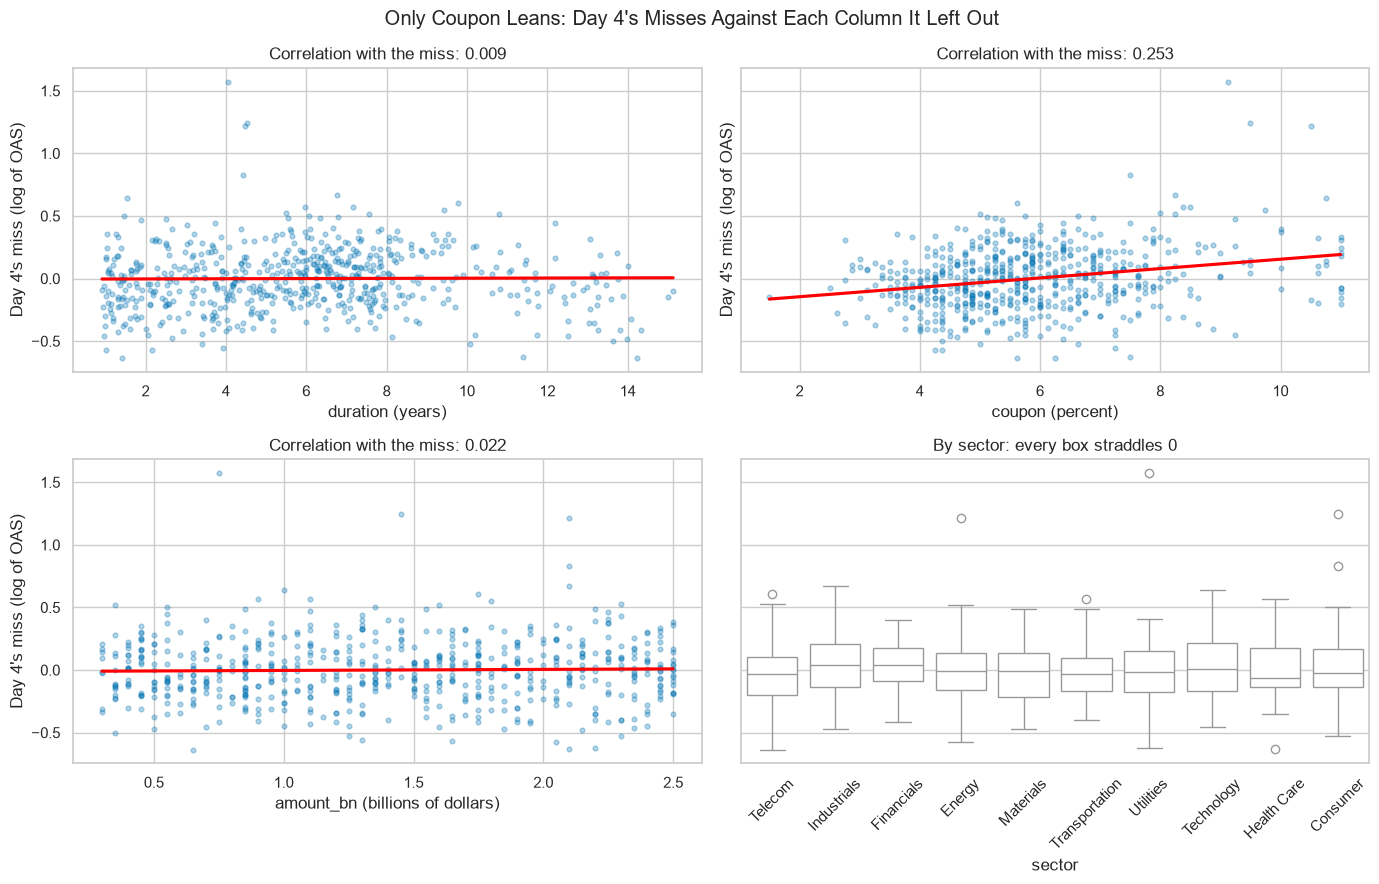

In [8]:
# Day 4's training misses against the three numbers it left out, each with a straight line, and by sector
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for ax, column, unit in zip(axes.flat, ["duration", "coupon", "amount_bn"], ["years", "percent", "billions of dollars"]):
    sns.regplot(x=train[column], y=day4_miss, ci=None, ax=ax, scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"})
    ax.set_xlabel(column + " (" + unit + ")")
    ax.set_title("Correlation with the miss: " + str(round(day4_miss.corr(train[column]), 3)))
sns.boxplot(x=train["sector"], y=day4_miss, color="white", ax=axes[1, 1])
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_title("By sector: every box straddles 0")
fig.suptitle("Only Coupon Leans: Day 4's Misses Against Each Column It Left Out")
plt.tight_layout()
plt.show()

Coupon leans, correlation 0.253; duration and amount sit near zero, at 0.009 and 0.022.

`ci=None` leaves out seaborn's band, which it draws from random resamples.

**Only coupon leans, and the issuer holds much of the rest. We give the model every column and let a penalty sort them out.**

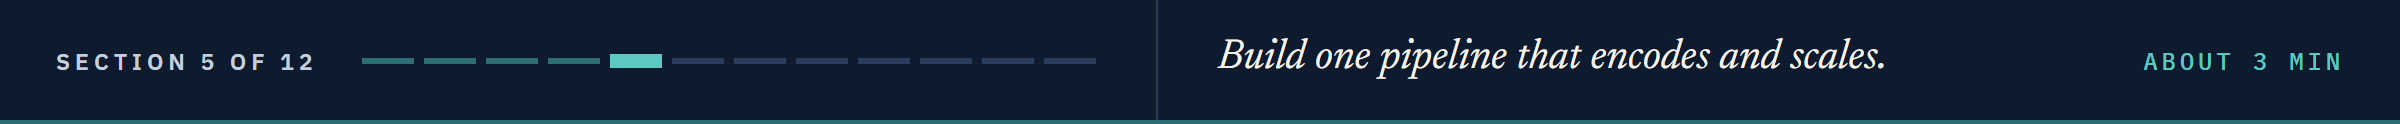

# Data Preparation for Modeling

## Turning Every Column Into Numbers

Three steps, named before they are used:

* `OneHotEncoder` makes Day 2's dummy columns as a model step: `categories=` lists every level in advance, `drop=` names the reference levels, A and Consumer.
* `StandardScaler` is Course 1's z-score as a step, with each column's mean and standard deviation learned from the rows it is fitted on.
* `ColumnTransformer` sends each column to its step and sets the results side by side.

Q. What does scaling do to four numbers on four scales?

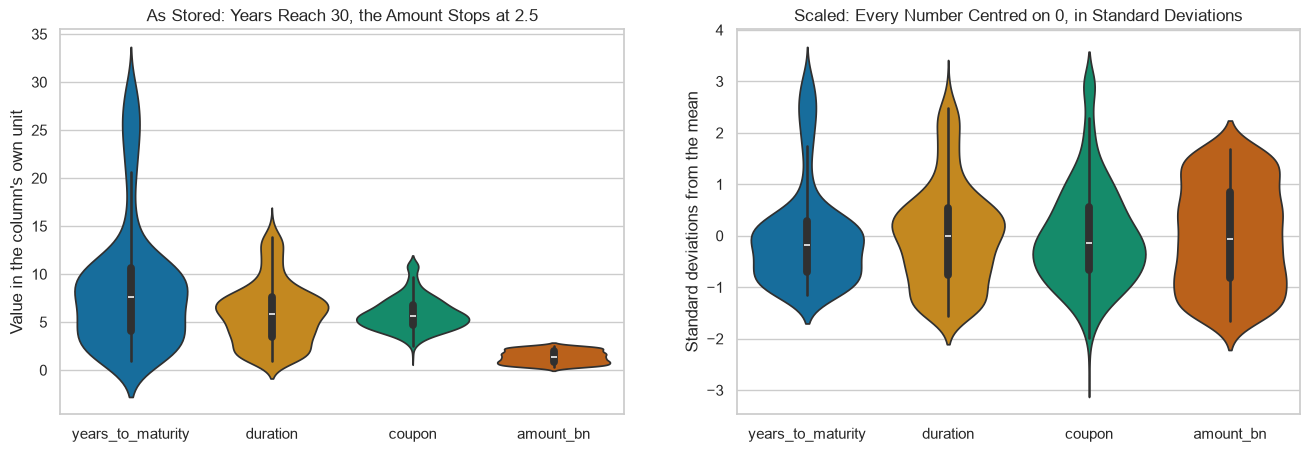

In [9]:
# a demonstration: the scaler on its own, fitted on the training bonds' four numbers
# fit_transform learns the means and standard deviations, then scales, in one call
scaled = pd.DataFrame(StandardScaler().fit_transform(train[NUMBERS]), columns=NUMBERS)

# each number as stored, then scaled
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.violinplot(data=train[NUMBERS], ax=axes[0])
sns.violinplot(data=scaled, ax=axes[1])
axes[0].set_ylabel("Value in the column's own unit")
axes[1].set_ylabel("Standard deviations from the mean")
axes[0].set_title("As Stored: Years Reach 30, the Amount Stops at 2.5")
axes[1].set_title("Scaled: Every Number Centred on 0, in Standard Deviations")
plt.show()

A violin plot draws a column's distribution as a shape, with a small box plot inside.

After scaling, one unit of any column is one standard deviation, so a penalty can charge every coefficient alike.

## One Pipeline

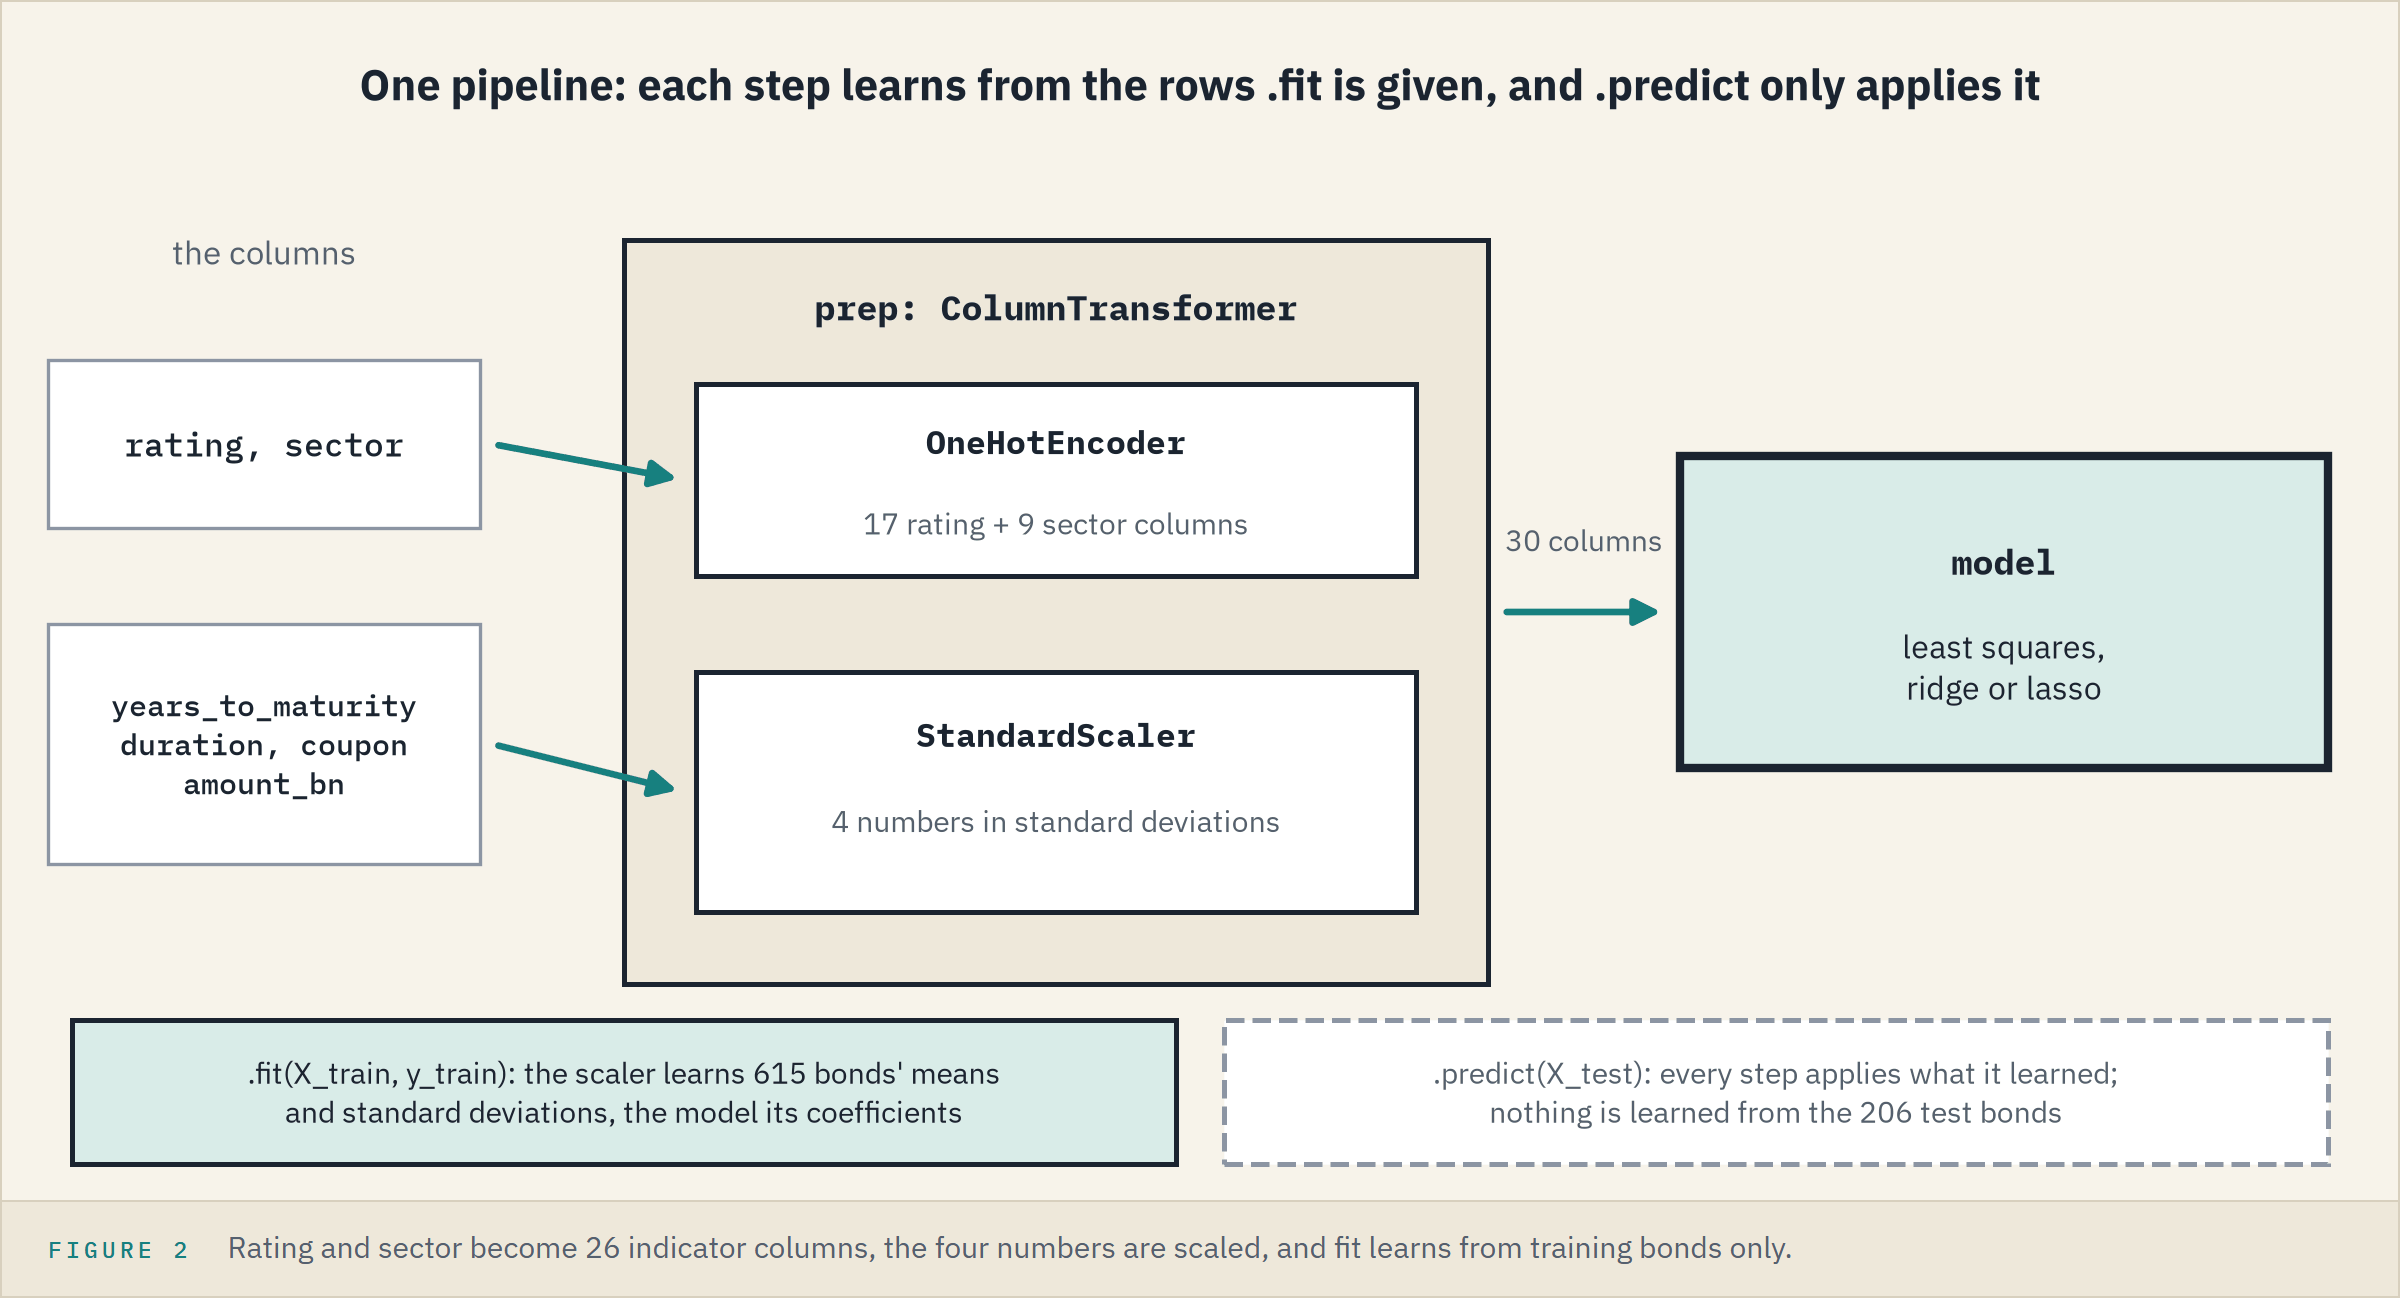

A `Pipeline` chains the steps and the model: `.fit` fits each in order on the rows it is given, and `.predict` only applies them.

In [10]:
# the file's 10 sectors, known in advance, and the columns every model reads
sectors = sorted(data["sector"].unique())
FEATURES = ["rating", "sector"] + NUMBERS
X_train, X_test = train[FEATURES], test[FEATURES]
y_train, y_test = train["log_oas"], test["log_oas"]

In [11]:
# one model: rating and sector into indicator columns, the four numbers scaled, then the regressor
# sparse_output=False: an ordinary table of 0.0 and 1.0; issuer=True adds one column per issuer (used later)
def make_model(regressor, numbers=NUMBERS, issuer=False):
    steps = [("categories", OneHotEncoder(categories=[rating_order, sectors], drop=["A", "Consumer"], sparse_output=False),
              ["rating", "sector"]),
             ("numbers", StandardScaler(), numbers)]
    if issuer:
        steps.append(("issuer", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["ticker"]))
    return Pipeline([("prep", ColumnTransformer(steps)), ("model", regressor)])

**Every column now goes through one object that learns from the rows it is fitted on, and only those.**

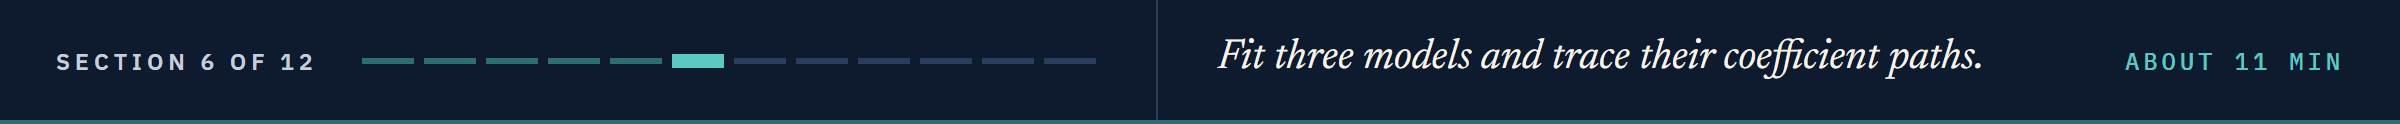

# Model Building

## Least Squares on All 30 Columns

In [12]:
# least squares in the pipeline, fitted on the training bonds
ols = make_model(LinearRegression()).fit(X_train, y_train)

# the columns the model received: pipe["prep"] picks out one step by its name
names = ols["prep"].get_feature_names_out()
print(len(names), "columns, the last six:", list(names[-6:]))

30 columns, the last six: ['categories__sector_Transportation', 'categories__sector_Utilities', 'numbers__years_to_maturity', 'numbers__duration', 'numbers__coupon', 'numbers__amount_bn']


17 rating columns, 9 sector columns and 4 numbers, each name led by its step's name.

### Which Rows Did the Scaler Learn From?

In [13]:
# .named_transformers_ picks one step of the ColumnTransformer by its name: here the fitted scaler
# the means it holds, beside the training bonds' means and the means of all 821 bonds
scaler = ols["prep"].named_transformers_["numbers"]
pd.DataFrame({"scaler": scaler.mean_, "training bonds": X_train[NUMBERS].mean(), "all bonds": data[NUMBERS].mean()})

,scaler,training bonds,all bonds
years_to_maturity,8.763,8.763,8.910
duration,5.918,5.918,5.981
coupon,5.873,5.873,5.852
amount_bn,1.394,1.394,1.392


The scaler holds the training bonds' means, not those of all 821 bonds.

**Encoding and scaling live inside the model, fitted on training bonds only.**

## Scoring in bp

As on Day 4, both logs go back through `exp` before a miss is measured.

In [14]:
# the typical miss and the root mean squared miss, in bp
def mae_bp(y_log, fitted_log):
    return mean_absolute_error(np.exp(y_log), np.exp(fitted_log))

def rmse_bp(y_log, fitted_log):
    return np.sqrt(mean_squared_error(np.exp(y_log), np.exp(fitted_log)))

**Predict 1**

Day 4's model misses unseen bonds by 33.1 bp with 18 columns.

With all 30, write down the test MAE in bp.

In [15]:
# least squares on bonds it has never seen, then on the bonds it was fitted on
ols_test = ols.predict(X_test)
print("Test MAE:", round(mae_bp(y_test, ols_test), 2), " Test RMSE:", round(rmse_bp(y_test, ols_test), 2))
print("Training MAE:", round(mae_bp(y_train, ols.predict(X_train)), 2))

Test MAE: 28.43  Test RMSE: 65.86
Training MAE: 34.53


28.43 bp, 4.7 bp below Day 4's model.

The training miss sits above the test miss again: as on Day 1, the luck of where the widest bonds fell.

**More columns, a smaller miss. But 30 coefficients on 615 bonds: how far should we trust each one? A penalty asks that.**

## Ridge: a Price on Every Coefficient

Ridge minimises the squared misses plus a charge: alpha times the sum of the squared coefficients.

At alpha 0 it is least squares; a large alpha pulls every coefficient toward zero.

Pulling coefficients toward zero is called **shrinkage**, or **regularization**.

In [16]:
# ridge with alpha 10, in the same pipeline
ridge10 = make_model(Ridge(alpha=10)).fit(X_train, y_train)

# both models' coefficients, named
ols_coefs = pd.Series(ols["model"].coef_, index=names)
ridge10_coefs = pd.Series(ridge10["model"].coef_, index=names)
print("Sum of squared coefficients: least squares", round((ols_coefs ** 2).sum(), 2), " ridge", round((ridge10_coefs ** 2).sum(), 2))
print("CCC+ step from A (log OAS): least squares", round(ols_coefs["categories__rating_CCC+"], 2),
      " ridge", round(ridge10_coefs["categories__rating_CCC+"], 2))

Sum of squared coefficients: least squares 17.79  ridge 2.48
CCC+ step from A (log OAS): least squares 1.85  ridge 0.38


### Why the Scaler Is in the Pipeline

The penalty trades training fit for smaller coefficients: the CCC+ step falls to a fifth of its size.

It charges a coefficient by its size, and that size depends on the column's unit.

Q. Coupon in percent or in bp is the same information. Does ridge treat it the same?

In [17]:
# three numbers, coupon once in percent and once in bp; ridge with alpha 100, first alone, then after a scaler
three = ["years_to_maturity", "duration", "coupon"]
in_bp = X_train[three].assign(coupon=X_train["coupon"] * 100)
for name, model in [("no scaler", Ridge(alpha=100)), ("scaler", Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=100))]))]:
    fitted_percent = np.exp(model.fit(X_train[three], y_train).predict(X_train[three]))
    fitted_in_bp = np.exp(model.fit(in_bp, y_train).predict(in_bp))
    print(name, " largest gap in a training bond's fitted spread:", round(np.abs(fitted_percent - fitted_in_bp).max(), 1), "bp")

no scaler  largest gap in a training bond's fitted spread: 83.2 bp
scaler  largest gap in a training bond's fitted spread: 0.0 bp


Without a scaler, changing a unit moves a fitted spread by up to 83.2 bp; with one, by 0.0.

Scaling makes the charge fair: every coefficient is priced per standard deviation.

## Lasso: a Price That Can Reach Zero

Lasso charges alpha times the sum of the coefficients' sizes, signs ignored, instead of their squares.

That charge can push a coefficient to exactly zero, which drops its column: lasso does **feature selection**.

scikit-learn scales the two charges differently, so a ridge alpha and a lasso alpha cannot be compared.

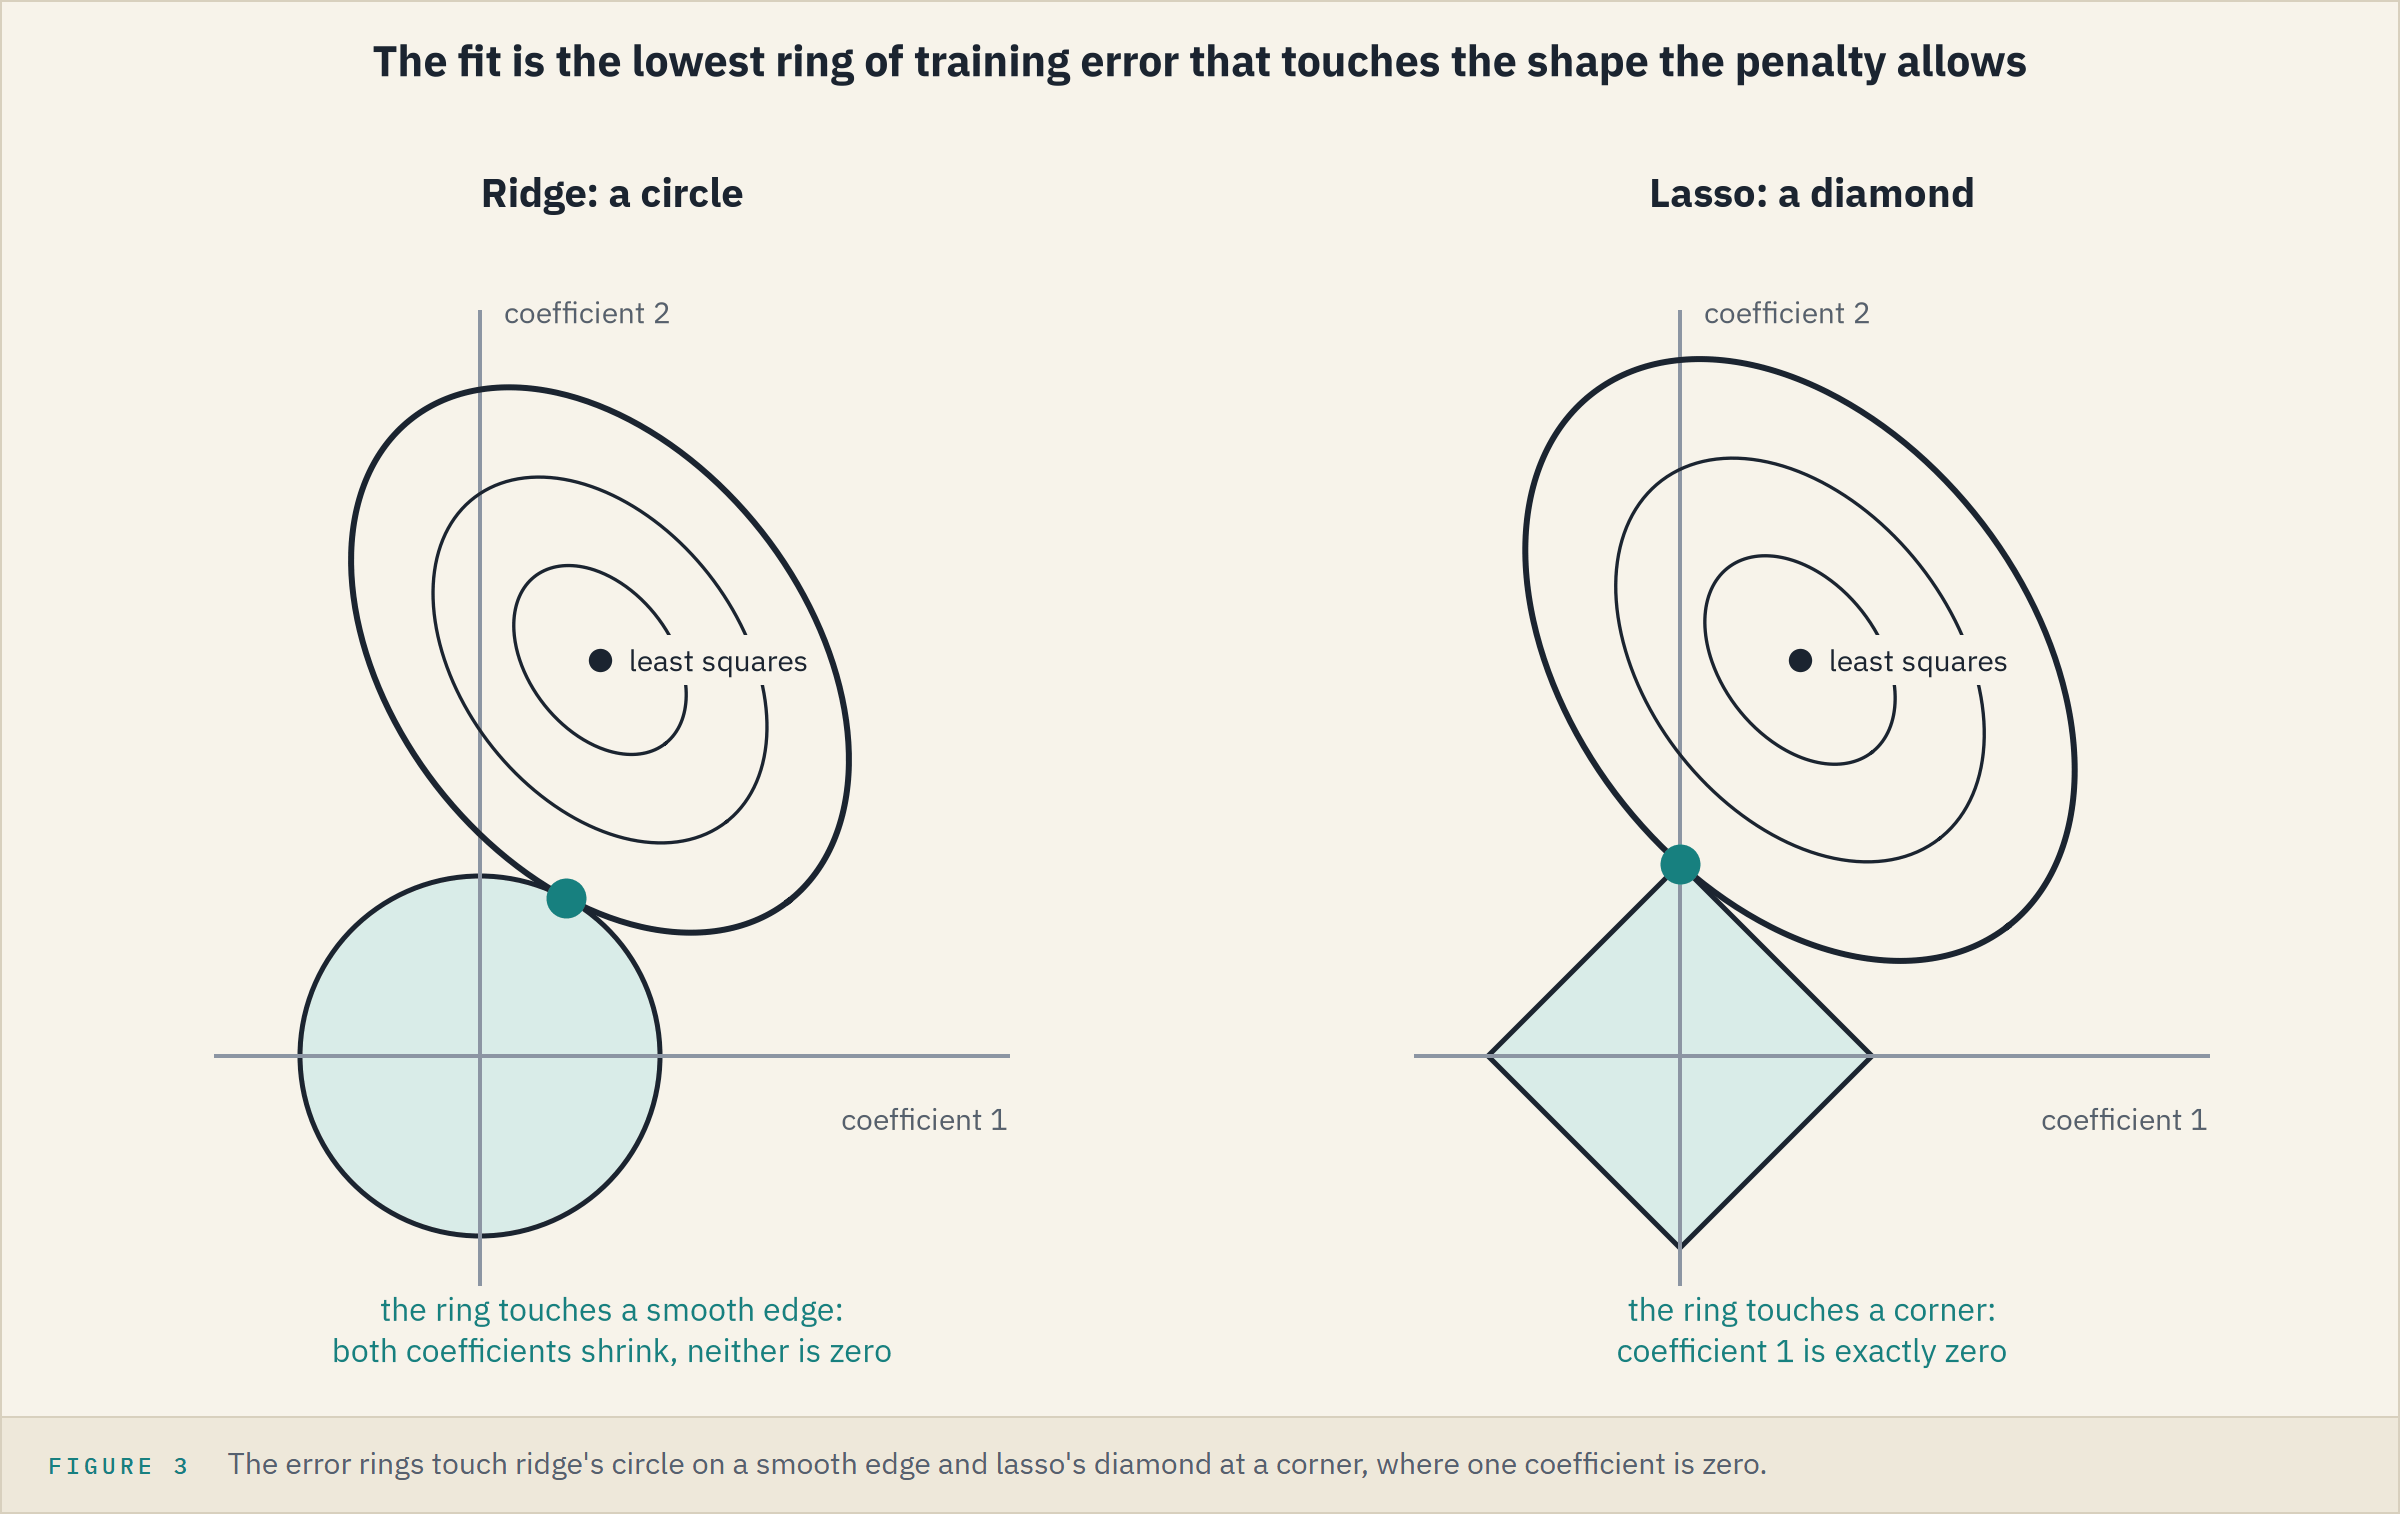

The rings are Day 3's error valley.

The fit is the lowest ring that touches the penalty's shape: a circle for ridge, a diamond for lasso, whose corners sit on the axes, where a coefficient is zero.

## Your Turn: Turn Up Lasso's Penalty

The slider sets alpha as a power of ten, from 0.0001 at -4 to 1 at 0.

Bars are blue for ratings, orange for sectors, green for the four numbers.

Q. Which colour empties first?

In [18]:
# each column's family, for its colour, and its name without the step's name
family = ["rating" if "rating_" in name else "sector" if "sector_" in name else "number" for name in names]
short = [name.split("__")[1] for name in names]
colours = {"rating": "tab:blue", "sector": "tab:orange", "number": "tab:green"}

# lasso at alpha = 10 to the power log_alpha: its 30 coefficients as bars, the zeros counted in the title
def draw_lasso(log_alpha=-2.0):
    lasso = make_model(Lasso(alpha=10 ** log_alpha)).fit(X_train, y_train)
    zeros = (lasso["model"].coef_ == 0).sum()
    plt.figure(figsize=(15, 5))
    plt.bar(short, lasso["model"].coef_, color=[colours[f] for f in family])
    plt.xticks(rotation=90)
    plt.ylabel("Coefficient (log OAS)")
    plt.title("Alpha " + str(round(10 ** log_alpha, 4)) + ": " + str(zeros) + " columns at zero, training MAE "
              + str(round(mae_bp(y_train, lasso.predict(X_train)), 1)) + " bp")
    plt.show()

In [19]:
# drag the slider from -4 to 0 in steps of 0.25
from ipywidgets import interact
interact(draw_lasso, log_alpha=(-4.0, 0.0, 0.25));

interactive(children=(FloatSlider(value=-2.0, description='log_alpha', max=0.0, min=-4.0, step=0.25), Output()…

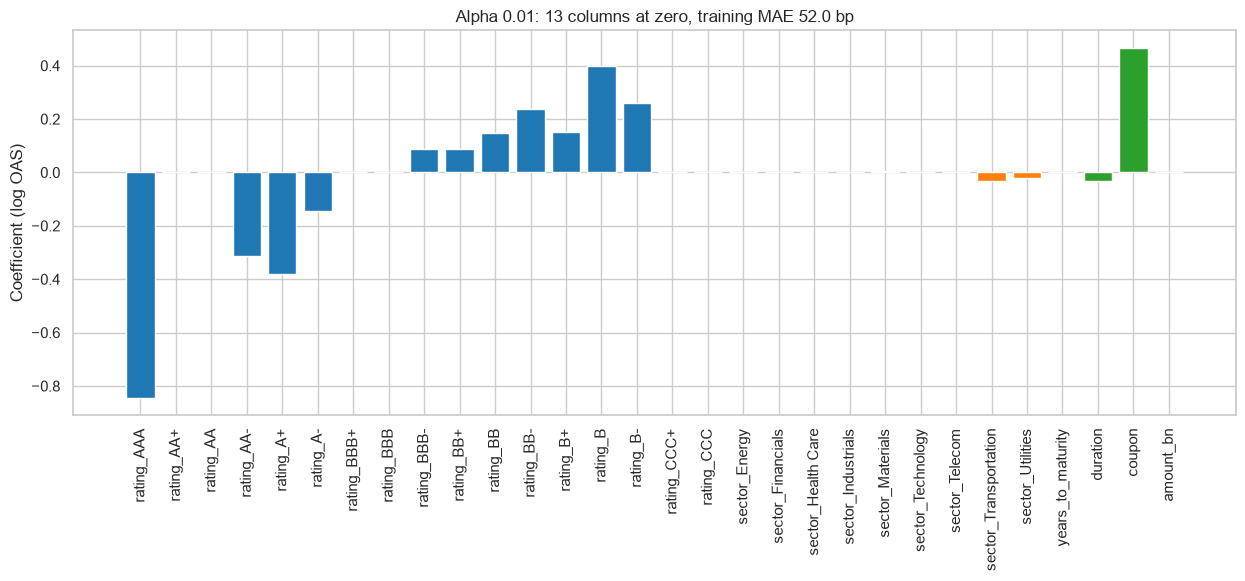

In [20]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_lasso(log_alpha=-2.0)

At alpha 0.01, 13 of the 30 bars are gone: six of the nine sectors, six ratings and one number.

The training miss climbs from 34.5 to 52.0 bp: lasso gives up fit to drop columns.

## Coefficient Paths

A **coefficient path** follows every coefficient as alpha grows.

`np.logspace(-3, 4, 57)` makes 57 alphas spaced evenly in powers of ten, from 0.001 to 10,000.

**Predict 2**

Ridge pulls coefficients toward zero as alpha grows.

Sketch coupon's coefficient from alpha 0.001 to 10,000.

In [21]:
# every coefficient at 57 ridge alphas and 41 lasso alphas, one row per alpha
ridge_alphas = np.logspace(-3, 4, 57)
lasso_alphas = np.logspace(-4, 0, 41)
ridge_path = pd.DataFrame([make_model(Ridge(alpha=a)).fit(X_train, y_train)["model"].coef_ for a in ridge_alphas],
                          index=ridge_alphas, columns=short)
lasso_path = pd.DataFrame([make_model(Lasso(alpha=a)).fit(X_train, y_train)["model"].coef_ for a in lasso_alphas],
                          index=lasso_alphas, columns=short)

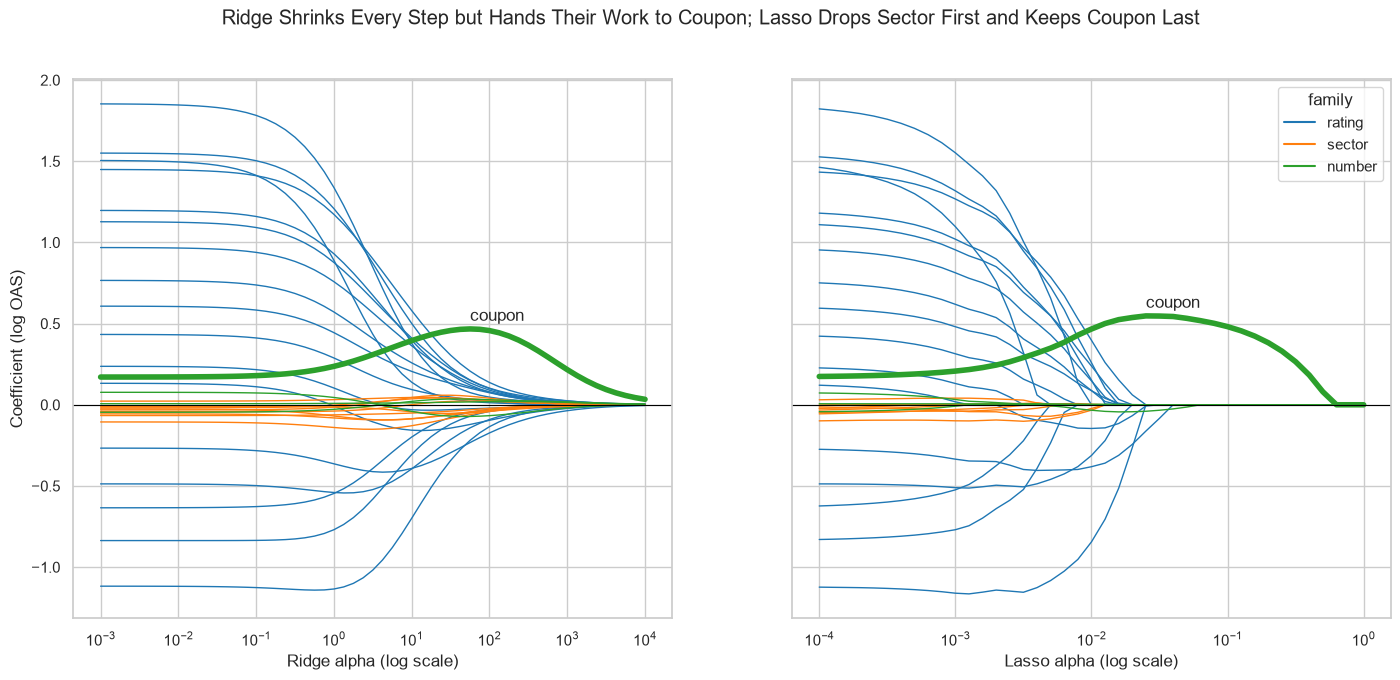

In [22]:
# one line per coefficient, coloured by family, coupon drawn thick; alpha on a log axis
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
for ax, path, name in [(axes[0], ridge_path, "Ridge"), (axes[1], lasso_path, "Lasso")]:
    for column, f in zip(short, family):
        ax.plot(path.index, path[column], color=colours[f], linewidth=4 if column == "coupon" else 1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xlabel(name + " alpha (log scale)")
    ax.text(path["coupon"].idxmax(), path["coupon"].max() + 0.05, "coupon")
for f, colour in colours.items():
    axes[1].plot([], [], color=colour, label=f)
axes[0].set_ylabel("Coefficient (log OAS)")
axes[1].legend(title="family")
fig.suptitle("Ridge Shrinks Every Step but Hands Their Work to Coupon; Lasso Drops Sector First and Keeps Coupon Last")
plt.show()

In [23]:
# ridge's coupon coefficient at its start and its peak, and the largest lasso alpha at which each column is not zero
# groupby(family) groups the 30 columns by the list of their families, one label per column
print("Ridge's coupon coefficient: from", round(ridge_path["coupon"].iloc[0], 3), "up to", round(ridge_path["coupon"].max(), 3),
      "at alpha", round(ridge_path["coupon"].idxmax(), 1))
last_alpha = pd.Series({column: lasso_path.index[lasso_path[column] != 0].max() for column in short})
print(last_alpha.groupby(family).max().round(4))
print(last_alpha[NUMBERS].round(4))

Ridge's coupon coefficient: from 0.171 up to 0.467 at alpha 56.2
number   0.501
rating   0.032
sector   0.013
dtype: float64
years_to_maturity   0.001
duration            0.050
coupon              0.501
amount_bn           0.020
dtype: float64


Ridge's coupon coefficient rises from 0.171 to 0.467 before it falls: as the rating steps shrink, coupon picks up their work.

Under lasso the last sector is still in at alpha 0.013 and the last rating at 0.032; coupon lasts to 0.5.

Of Day 3's near-copies, lasso keeps duration (to 0.05) long after years to maturity (to 0.001): one of the two, and not the recipe's.

**The penalty decides how far each coefficient moves. Which alpha? The training bonds choose it.**

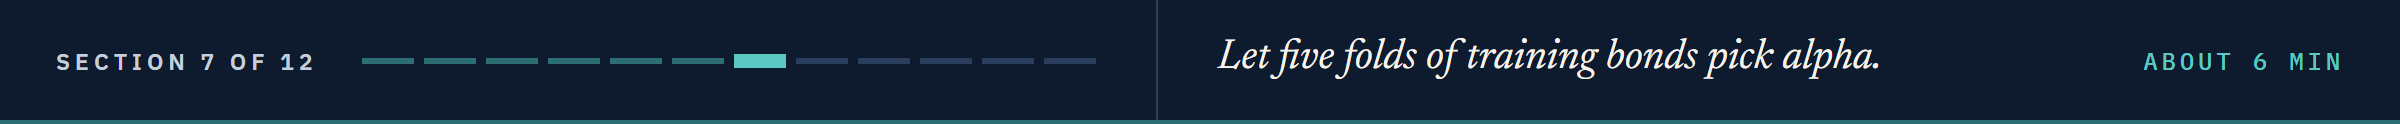

# Choosing Alpha

## Folds of the Training Bonds

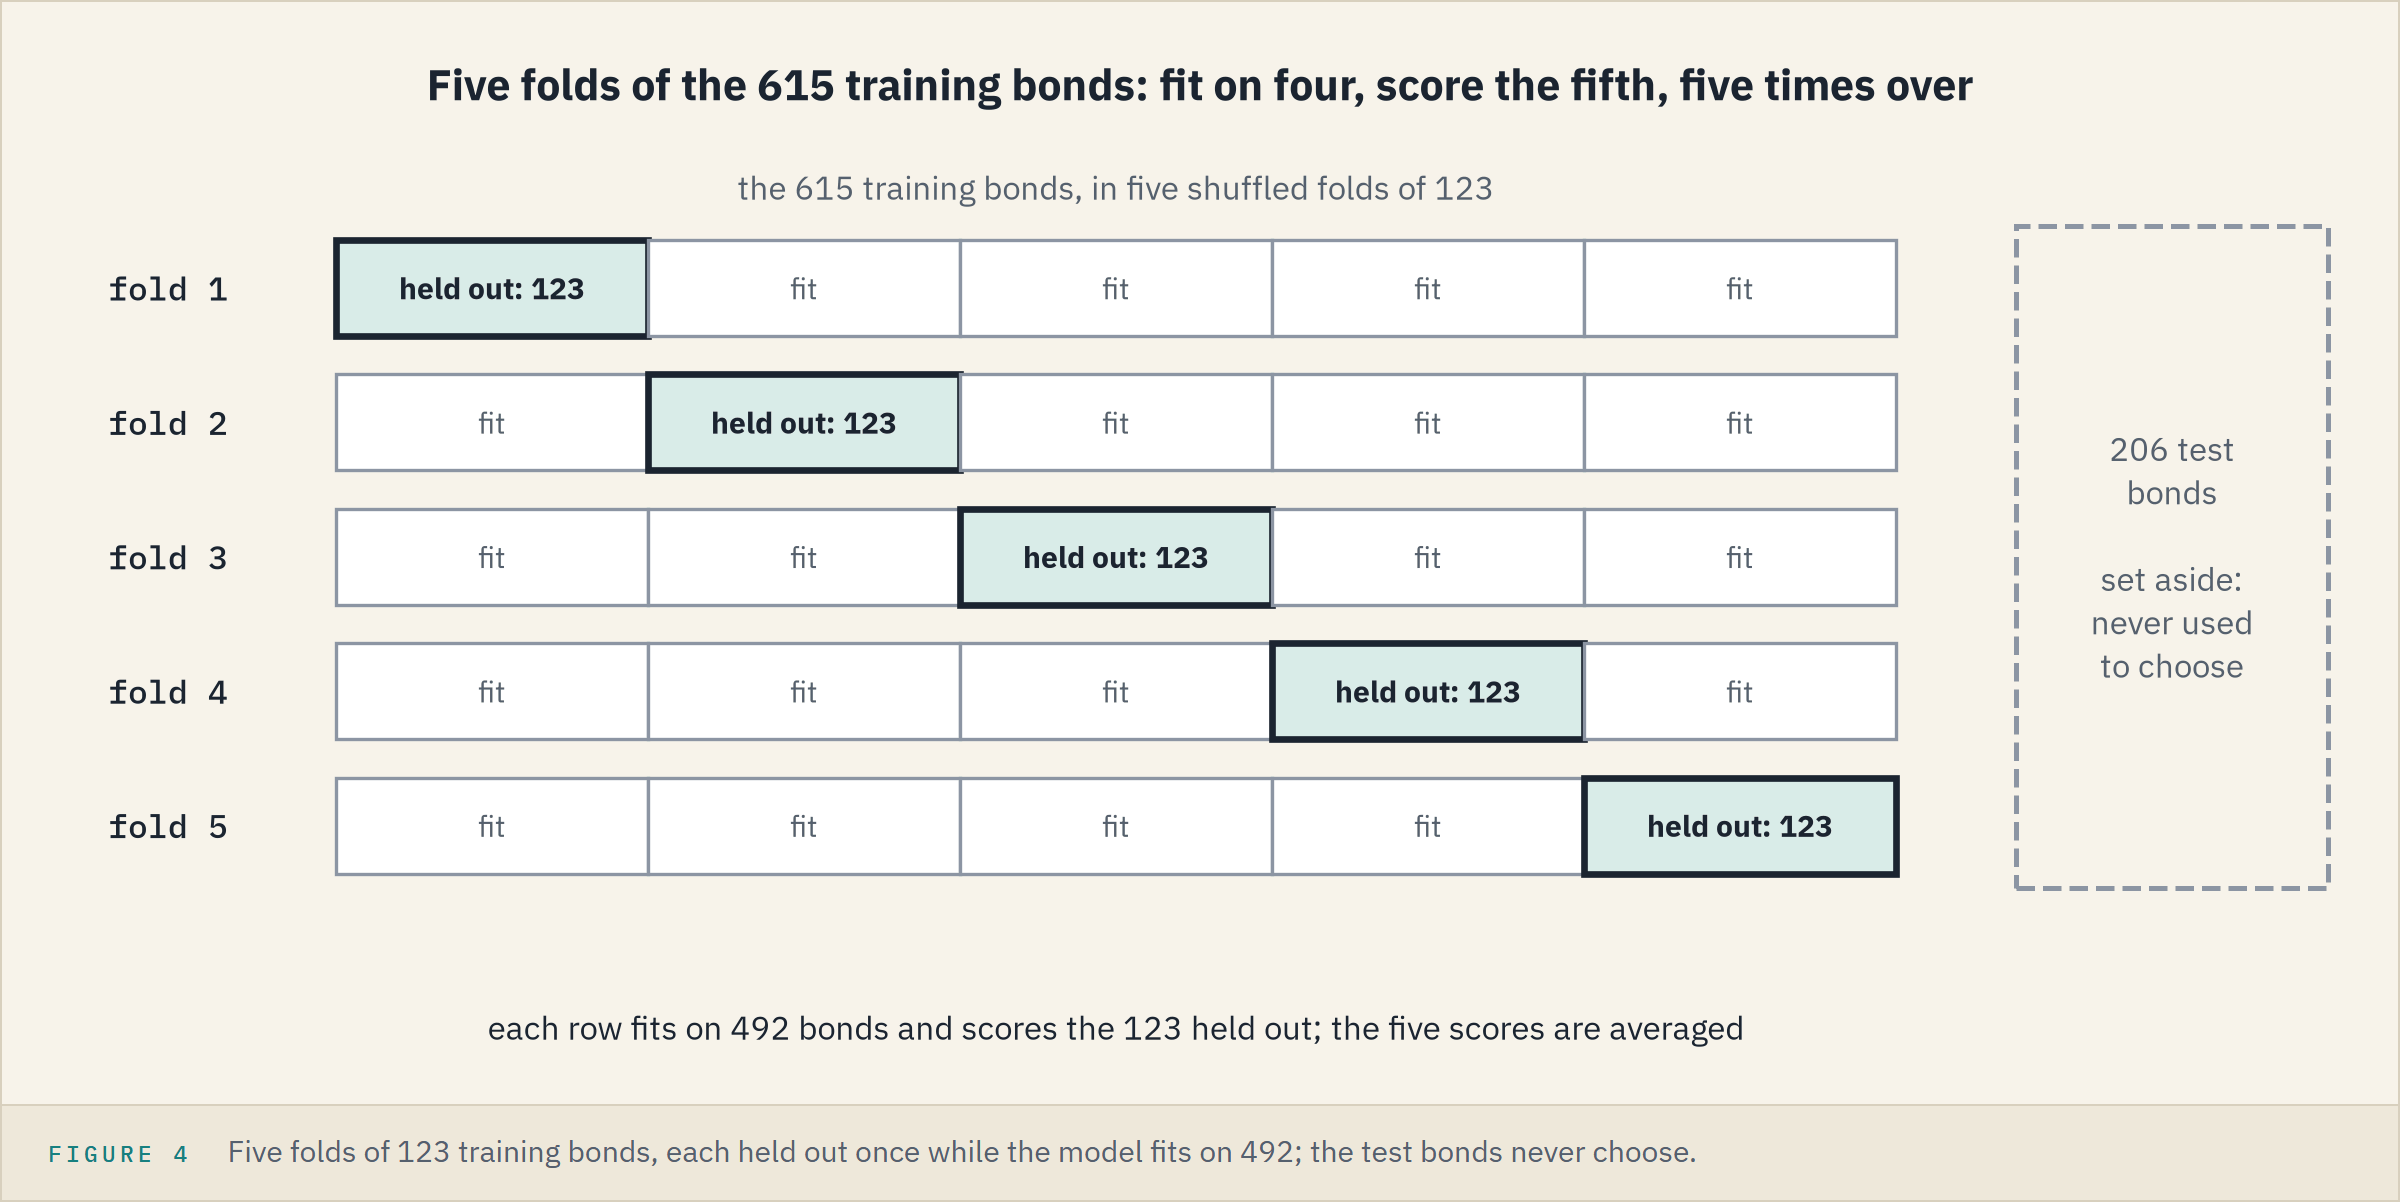

**Cross-validation** fits on four folds of the training bonds and scores the fifth, once per fold.

The average judges an alpha without the test bonds; the spread of the five shows how much the rows move a number.

In [24]:
# five folds of the training bonds, shuffled with the seed
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
for fit_rows, held_out_rows in folds.split(X_train):
    print("fit on", len(fit_rows), " score on", len(held_out_rows))

fit on 492  score on 123
fit on 492  score on 123
fit on 492  score on 123
fit on 492  score on 123
fit on 492  score on 123


## Scoring One Alpha on Every Fold

`cross_val_score` runs that loop for one model and returns one score per held-out fold; a regressor's score is R-squared unless we say otherwise.

In [25]:
# ridge's held-out R-squared on each fold, for 13 alphas from 0.001 to 1,000; the mean over the folds
ridge_grid = np.logspace(-3, 3, 13)
ridge_scores = pd.DataFrame([cross_val_score(make_model(Ridge(alpha=a)), X_train, y_train, cv=folds) for a in ridge_grid],
                            index=ridge_grid)
ridge_scores.mean(axis=1)

0.001       0.897
0.003       0.897
0.010       0.897
0.032       0.897
0.100       0.897
0.316       0.896
1.000       0.885
3.162       0.850
10.000      0.783
31.623      0.707
100.000     0.636
316.228     0.531
1,000.000   0.337
dtype: float64

The mean R-squared holds at 0.897 from 0.001 to 0.1, then falls as the penalty bites.

Q. Each fold fits its own pipeline. Did each learn its own scaler?

In [26]:
# cross_validate keeps each fold's fitted pipeline: duration's mean in each fold's scaler, then in all 615 training bonds
fold_models = cross_validate(make_model(Ridge(alpha=1)), X_train, y_train, cv=folds, return_estimator=True)["estimator"]
print(pd.Series([model["prep"].named_transformers_["numbers"].mean_[1] for model in fold_models]).round(4).tolist())
print(round(X_train["duration"].mean(), 4))

[5.9015, 5.9824, 5.927, 5.845, 5.932]
5.9176


## RidgeCV and LassoCV

Five different means: each fold scales on its own 492 bonds, so a held-out fold never shapes its own scaling.

`RidgeCV` and `LassoCV` run the whole search themselves and keep the winner in `.alpha_`.

Left alone, `LassoCV` makes its own grid of 100 alphas, kept in `.alphas_`.

In [27]:
# ridge on our 13 alphas, lasso on its own grid; both judged on the same five folds
ridge_cv = make_model(RidgeCV(alphas=ridge_grid, cv=folds)).fit(X_train, y_train)
lasso_own = make_model(LassoCV(cv=folds, random_state=SEED)).fit(X_train, y_train)
print("Ridge's alpha:", round(ridge_cv["model"].alpha_, 4))
print("Lasso's alpha:", round(lasso_own["model"].alpha_, 6), " smallest on its grid:", round(lasso_own["model"].alphas_.min(), 6))

Ridge's alpha: 0.0316
Lasso's alpha: 0.000581  smallest on its grid: 0.000581


Ridge picks 0.0316, where the loop's mean is highest once more decimals show.

Inside the pipeline both search rows scaled once on all 615 training bonds, not fold by fold; the same choice as the loop shows how little that moves here.

Lasso picks the smallest alpha its grid holds: a choice at the edge of a grid is not a choice, because a better alpha may lie past it.

In [28]:
# a grid that reaches further: 21 alphas from 0.00001 to 1
lasso_grid = np.logspace(-5, 0, 21)
lasso_cv = make_model(LassoCV(alphas=lasso_grid, cv=folds, random_state=SEED)).fit(X_train, y_train)
print("Lasso's alpha:", round(lasso_cv["model"].alpha_, 6))

Lasso's alpha: 0.000178


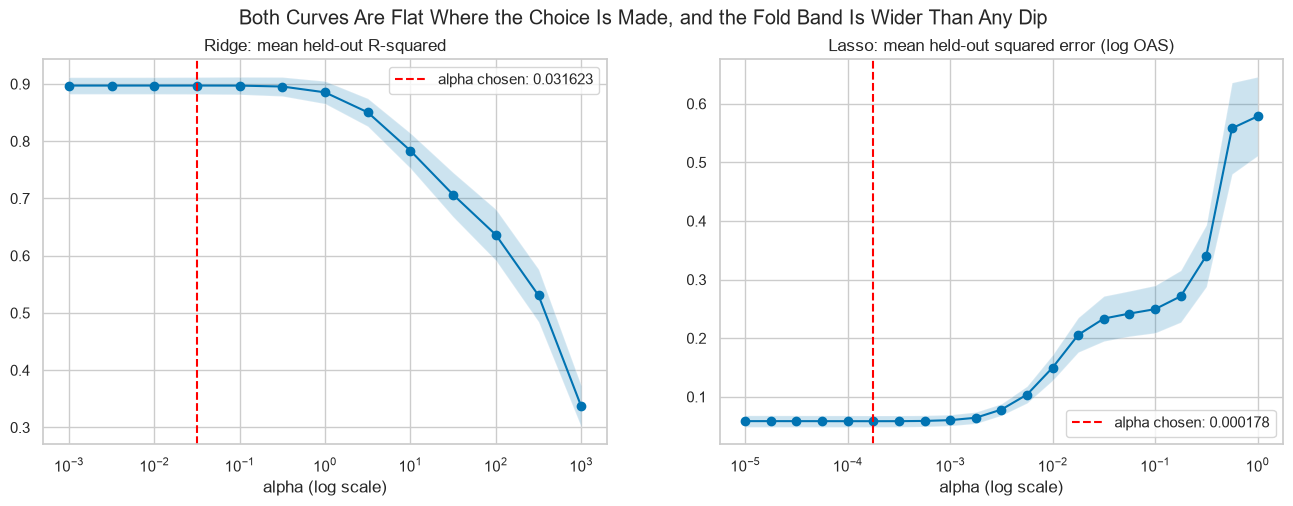

In [29]:
# how sharp is each choice? Held-out score against alpha, a band of one standard deviation across the folds, the choice dashed
lasso_mse = pd.DataFrame(lasso_cv["model"].mse_path_, index=lasso_cv["model"].alphas_)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, scores, chosen, name in [(axes[0], ridge_scores, ridge_cv["model"].alpha_, "Ridge: mean held-out R-squared"),
                                 (axes[1], lasso_mse, lasso_cv["model"].alpha_, "Lasso: mean held-out squared error (log OAS)")]:
    mean, spread = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(scores.index, mean, marker="o")
    ax.fill_between(scores.index, mean - spread, mean + spread, alpha=0.2)
    ax.axvline(chosen, color="red", linestyle="--", label="alpha chosen: " + str(round(chosen, 6)))
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_title(name)
    ax.legend()
fig.suptitle("Both Curves Are Flat Where the Choice Is Made, and the Fold Band Is Wider Than Any Dip")
plt.show()

`.mse_path_` holds lasso's squared error on every fold at every alpha; 0.000178 now sits inside the grid.

These are **validation curves**: a held-out score against the setting being chosen.

Both are flat across the small alphas, and the fold band is wider than any dip.

**Cross-validation picks a small penalty: these bonds want almost none.**

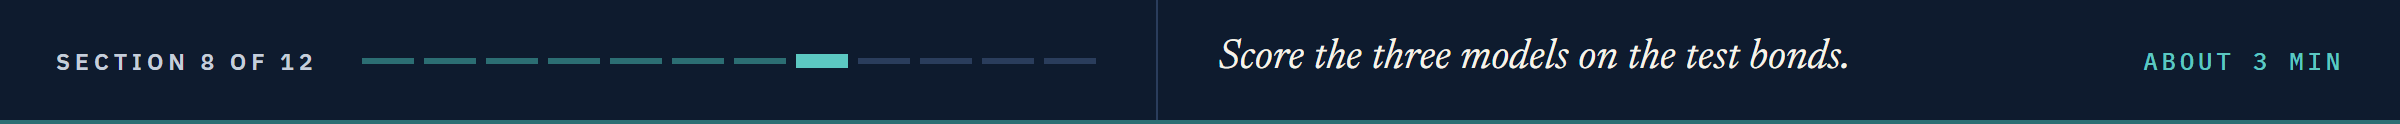

# Model Performance Evaluation

## The Three Models on the Test Bonds

**Predict 3**

Least squares misses the test bonds by 28.4 bp.

Write down ridge's and lasso's test MAE in bp.

In [30]:
# the three models on bonds they have never seen, in bp, and the most any coefficient moved from least squares
test_table = pd.DataFrame(index=["least squares", "ridge", "lasso"], columns=["test MAE", "test RMSE", "largest change"])
for name, model in zip(test_table.index, [ols, ridge_cv, lasso_cv]):
    fitted = model.predict(X_test)
    test_table.loc[name] = [mae_bp(y_test, fitted), rmse_bp(y_test, fitted), np.abs(model["model"].coef_ - ols_coefs).max()]
test_table

,test MAE,test RMSE,largest change
least squares,28.433,65.864,0.000
ridge,28.445,66.161,0.030
lasso,28.356,66.307,0.076


A tie: 28.43, 28.44 and 28.36 bp.

Ridge moved no coefficient by more than 0.030, lasso by 0.076.

## How Much One Split Moves a Number

`make_scorer` turns `mae_bp` into a score for `cross_val_score`.

`greater_is_better=False` says smaller is better, so scikit-learn hands it back with a minus sign, which we flip.

In [31]:
# MAE in bp on each held-out fold, for least squares and the two models that choose their own alpha
bp_scorer = make_scorer(mae_bp, greater_is_better=False)
regressors = {"least squares": LinearRegression(), "ridge": RidgeCV(alphas=ridge_grid, cv=folds),
              "lasso": LassoCV(alphas=lasso_grid, cv=folds, random_state=SEED)}
fold_mae = pd.DataFrame({name: -cross_val_score(make_model(regressor), X_train, y_train, cv=folds, scoring=bp_scorer)
                         for name, regressor in regressors.items()}, index=[1, 2, 3, 4, 5])
fold_mae

,least squares,ridge,lasso
1,28.789,28.792,28.832
2,34.933,34.911,34.521
3,55.971,55.970,55.769
4,31.713,31.652,31.572
5,34.532,34.524,34.354


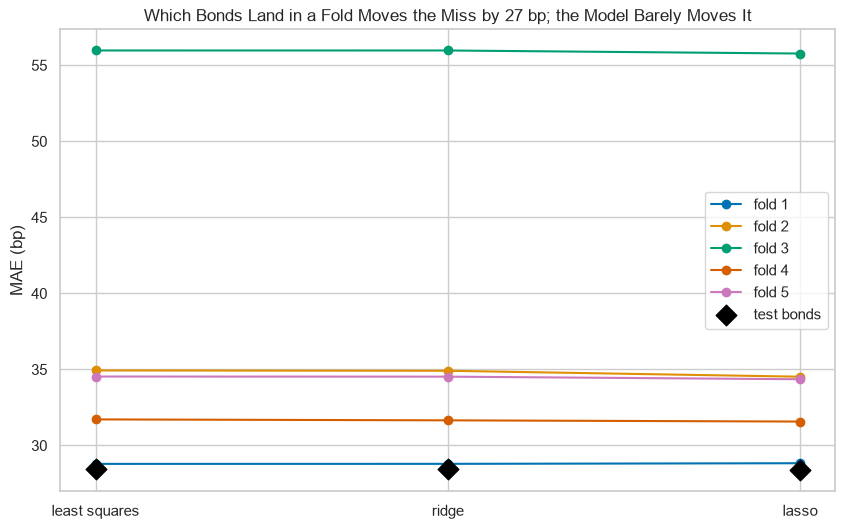

[0, 0, 3, 0, 2]


In [32]:
# one line per fold across the three models, each model's test MAE as a black diamond
plt.figure(figsize=(10, 6))
for fold, row in fold_mae.iterrows():
    plt.plot(row.index, row.values, marker="o", label="fold " + str(fold))
plt.scatter(test_table.index, test_table["test MAE"], marker="D", s=110, color="black", zorder=3, label="test bonds")
plt.ylabel("MAE (bp)")
plt.title("Which Bonds Land in a Fold Moves the Miss by 27 bp; the Model Barely Moves It")
plt.legend()
plt.show()

# training bonds above 1,000 bp in each held-out fold
print(pd.Series([(train["oas"].iloc[rows] > 1000).sum() for _, rows in folds.split(X_train)]).tolist())

This is an interaction plot: one line per fold, read across the models.

Least squares misses its folds by 28.8 to 56.0 bp: fold 3 holds three of the five training bonds above 1,000 bp.

In any one fold the three models sit within 0.5 bp of each other.

**The rows in a fold move the miss by 27 bp; the model moves the test miss by under 0.1 bp. 615 bonds and 30 columns leave a penalty little to fix.**

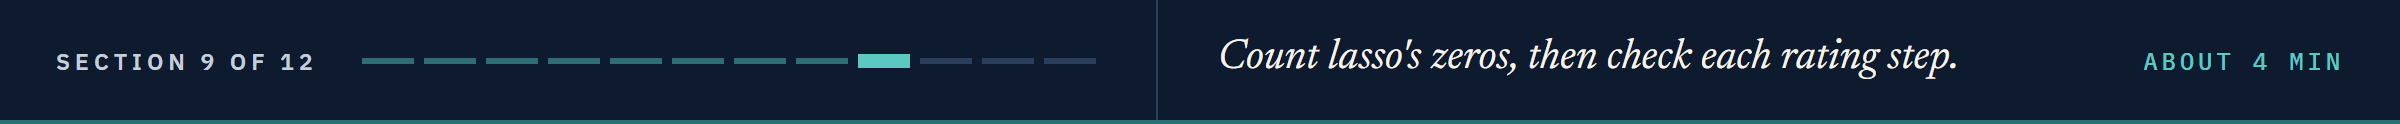

# Reading the Coefficients

## Which Columns Lasso Keeps

**Predict 4**

At the alpha cross-validation chose, how many of lasso's 30 coefficients sit at exactly zero?

In [33]:
# lasso's coefficients at its chosen alpha that are exactly zero
lasso_coefs = pd.Series(lasso_cv["model"].coef_, index=names)
print(lasso_coefs[lasso_coefs == 0])

# least squares' three sector coefficients closest to zero, by size
ols_coefs[ols_coefs.index.str.contains("sector_")].abs().sort_values().head(3)

categories__sector_Technology   0.000
dtype: float64


categories__sector_Technology    0.012
categories__sector_Industrials   0.019
categories__sector_Financials    0.022
dtype: float64

One: Technology, the sector least squares already put closest to zero.

Q. How does lasso's choice change as alpha grows?

`.filter(like="rating_")` keeps the columns whose names hold that text, and `plt.stackplot` piles one area on another.

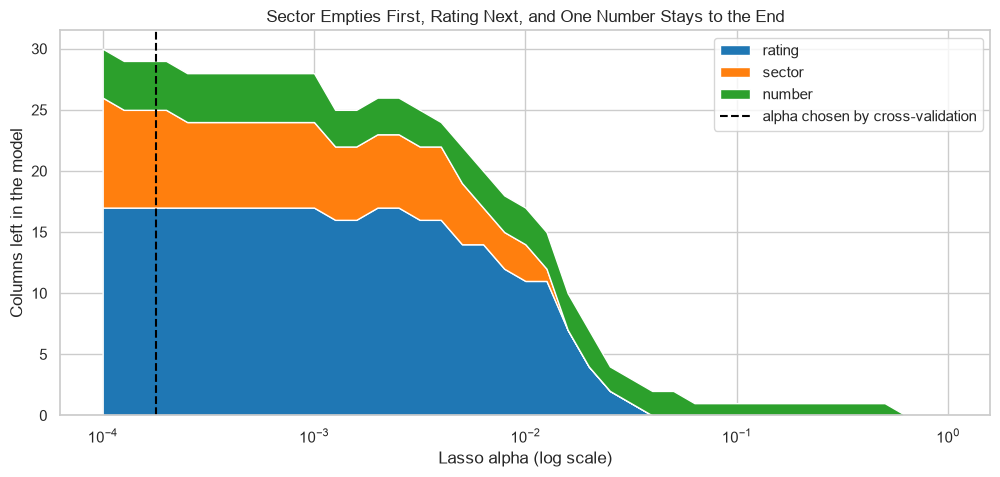

In [34]:
# how many columns of each family lasso keeps at each of its 41 alphas
in_model = lasso_path != 0
kept = pd.DataFrame({"rating": in_model.filter(like="rating_").sum(axis=1),
                     "sector": in_model.filter(like="sector_").sum(axis=1),
                     "number": in_model[NUMBERS].sum(axis=1)})

# the counts stacked on top of each other, the chosen alpha dashed
plt.figure(figsize=(12, 5))
plt.stackplot(kept.index, kept["rating"], kept["sector"], kept["number"], labels=list(colours), colors=list(colours.values()))
plt.axvline(lasso_cv["model"].alpha_, color="black", linestyle="--", label="alpha chosen by cross-validation")
plt.xscale("log")
plt.xlabel("Lasso alpha (log scale)")
plt.ylabel("Columns left in the model")
plt.title("Sector Empties First, Rating Next, and One Number Stays to the End")
plt.legend()
plt.show()

The recipe behind the file builds each spread from the rating, the years to maturity, the issuer and noise (Day 4's picture): no sector, no amount.

Coupon is set from each bond's own yield, the Treasury yield plus the OAS, so it carries part of the answer.

**The sectors, which the recipe never used, empty first; but at the chosen alpha lasso keeps 29 of 30 columns.**

## Rating Steps Against the Recipe

### What Coupon Does to the Steps

The recipe's spread for a 10-year bond of each rating gives its true step from A: the log of that spread over A's 80 bp.

In [35]:
# least squares without coupon, scored on the test bonds
no_coupon = make_model(LinearRegression(), numbers=["years_to_maturity", "duration", "amount_bn"]).fit(X_train, y_train)
no_coupon_coefs = pd.Series(no_coupon["model"].coef_, index=no_coupon["prep"].get_feature_names_out())
print("Test MAE without coupon:", round(mae_bp(y_test, no_coupon.predict(X_test)), 2), "bp")

Test MAE without coupon: 32.6 bp


In [36]:
# the recipe's typical spread for a 10-year bond of each rating (Day 4), and every step from A in logs, A at 0
recipe = pd.Series([30, 40, 48, 56, 68, 80, 95, 115, 135, 165, 215, 260, 310, 370, 440, 530, 720, 900], index=rating_order)
step_names = "categories__rating_" + recipe.index
steps = pd.DataFrame({"recipe": np.log(recipe / recipe["A"]),
                      "with_coupon": ols_coefs.reindex(step_names).fillna(0).values,
                      "without_coupon": no_coupon_coefs.reindex(step_names).fillna(0).values})

# the 17 steps within 0.2 of the recipe, the average gap, and coupon's correlation with log OAS
gaps = steps[["with_coupon", "without_coupon"]].sub(steps["recipe"], axis=0).drop("A")
print((gaps.abs() < 0.2).sum())
print(gaps.mean().round(2))
print("Coupon and log OAS:", round(train["coupon"].corr(train["log_oas"]), 2))

with_coupon        8
without_coupon    14
dtype: int64
with_coupon      -0.230
without_coupon   -0.080
dtype: float64
Coupon and log OAS: 0.77


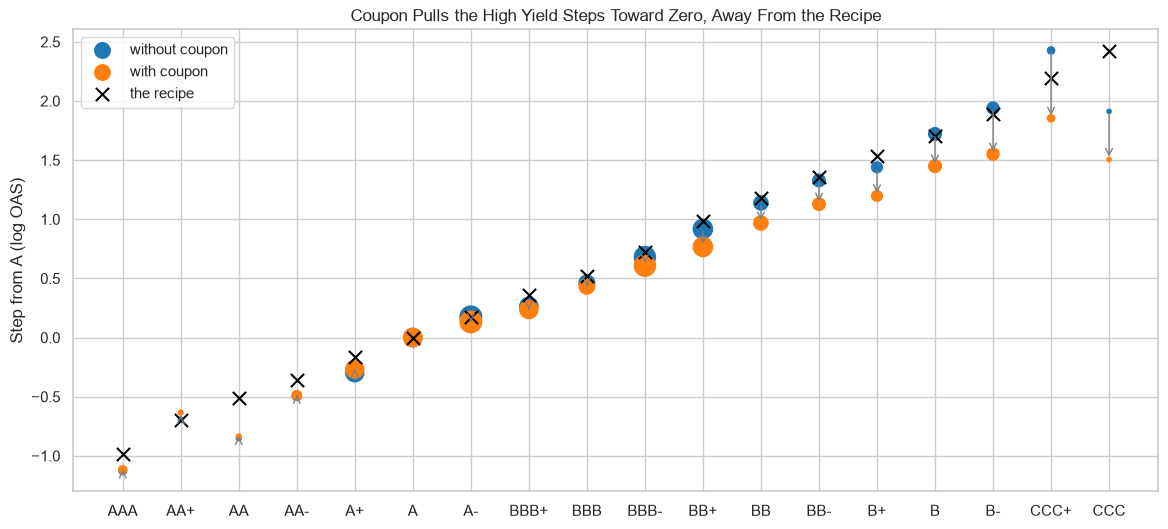

In [37]:
# one arrow per rating, from the step without coupon to the step with it; the recipe as crosses, dots sized by training bonds
counts = train["rating"].value_counts().reindex(rating_order)
position = np.arange(len(rating_order))
plt.figure(figsize=(14, 6))
for x, rating in enumerate(rating_order):
    plt.annotate("", xy=(x, steps.loc[rating, "with_coupon"]), xytext=(x, steps.loc[rating, "without_coupon"]),
                 arrowprops={"arrowstyle": "->", "color": "gray"})
plt.scatter(position, steps["without_coupon"], s=counts * 3, color="tab:blue", label="without coupon")
plt.scatter(position, steps["with_coupon"], s=counts * 3, color="tab:orange", label="with coupon")
plt.scatter(position, steps["recipe"], marker="x", s=90, color="black", label="the recipe")
plt.xticks(position, rating_order)
plt.ylabel("Step from A (log OAS)")
plt.title("Coupon Pulls the High Yield Steps Toward Zero, Away From the Recipe")
plt.legend()
plt.show()

Without coupon, 14 of the 17 steps sit within 0.2 of the recipe, 0.08 low on average; with it, 8 of 17, 0.23 low.

Coupon correlates 0.77 with log OAS: it takes over part of the rating's work, so the steps shrink.

AA and CCC miss the recipe either way: 4 and 3 training bonds.

**Coupon cuts the miss by 4.2 bp and bends the steps toward zero: a column that carries the answer improves the score and spoils the reading.**

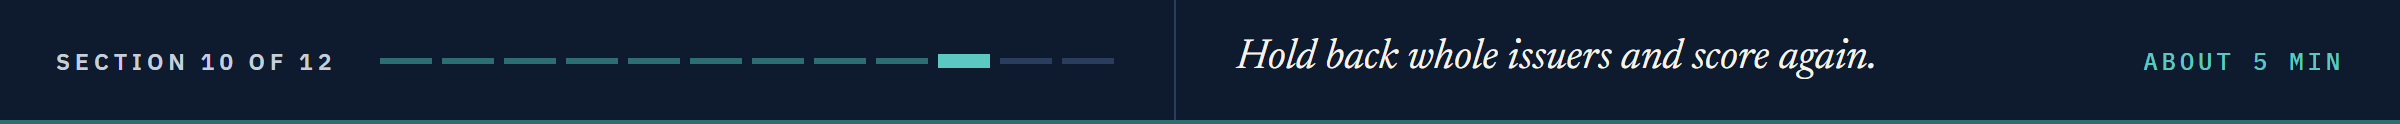

# The Split by Issuer

## A New Issuer

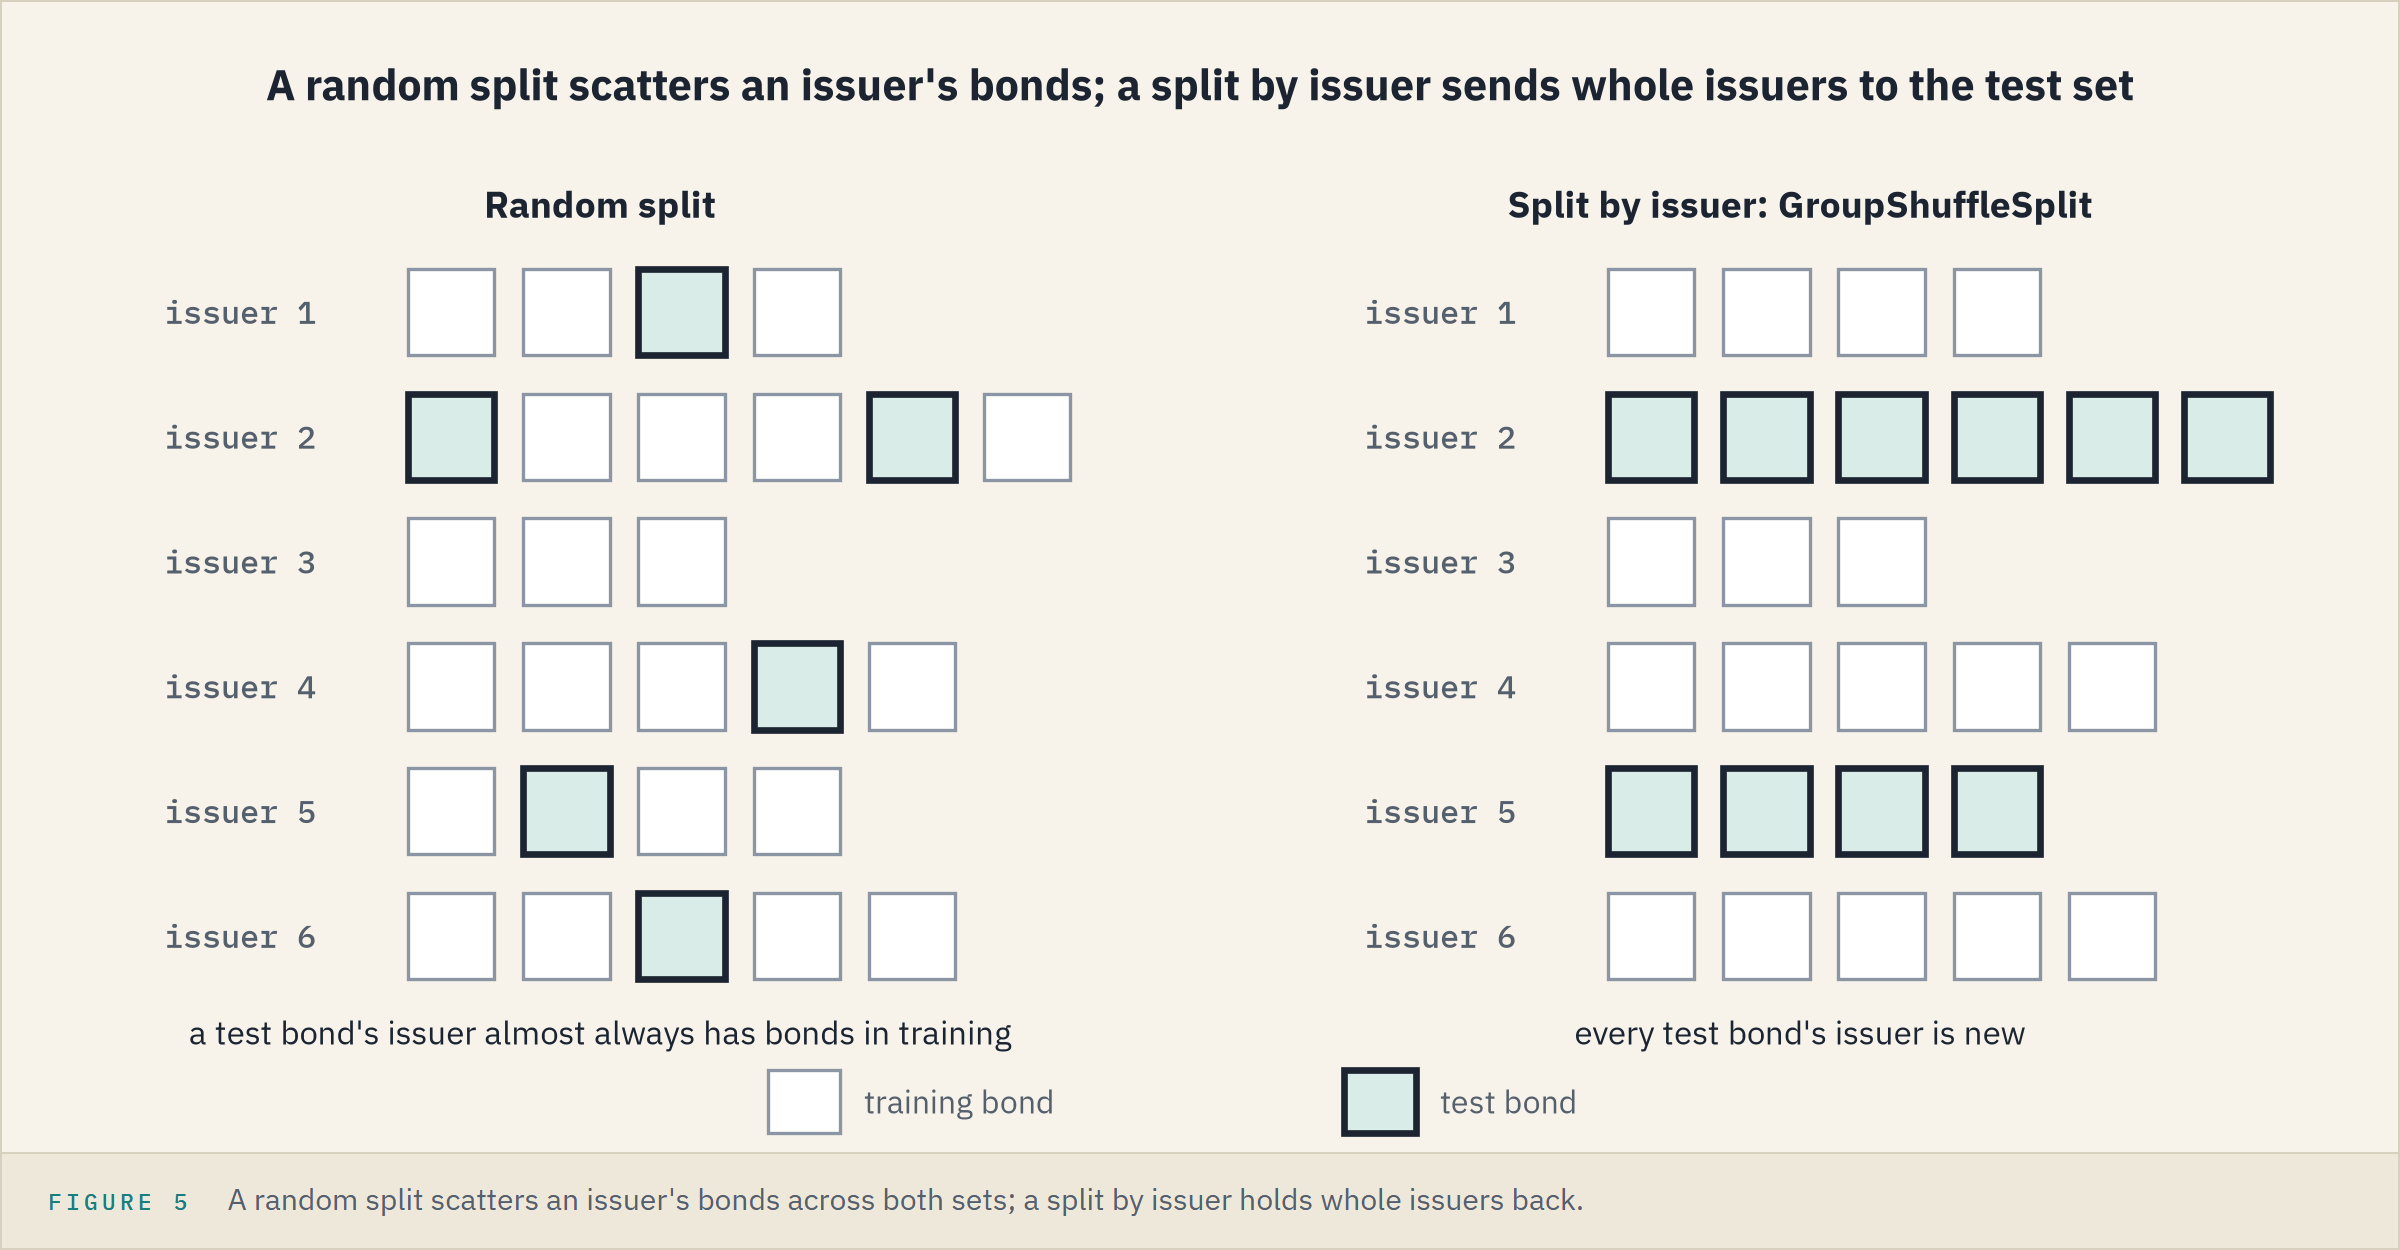

Day 1 found that 203 of the 206 test bonds share an issuer with a training bond.

`GroupShuffleSplit` holds back whole groups instead, here whole issuers, named by `groups=`; `next(...)` takes the first split it makes.

In [38]:
# a quarter of the issuers held back whole, with the seed
by_issuer = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
fit_rows, new_rows = next(by_issuer.split(data, groups=data["ticker"]))
issuer_train, issuer_test = data.iloc[fit_rows], data.iloc[new_rows]
shared = set(issuer_train["ticker"]) & set(issuer_test["ticker"])
print(len(issuer_train), "and", len(issuer_test), "bonds;", issuer_test["ticker"].nunique(), "test issuers;", len(shared), "shared")

631 and 190 bonds; 38 test issuers; 0 shared


In [39]:
# least squares on the issuer split, scored on the new issuers' bonds
new_issuer_model = make_model(LinearRegression()).fit(issuer_train[FEATURES], issuer_train["log_oas"])
new_fitted = new_issuer_model.predict(issuer_test[FEATURES])
print("Test MAE, new issuers:", round(mae_bp(issuer_test["log_oas"], new_fitted), 2), "bp")

# the largest miss, and the high yield bonds in each test set
misses = (issuer_test["oas"] - np.exp(new_fitted)).abs()
widest = issuer_test.loc[misses.idxmax()]
print(widest["issuer"], widest["cusip"], widest["rating"], widest["oas"], "bp, missed by", round(misses.max(), 1), "bp")
print("High yield test bonds:", (issuer_test["grade"] == "High Yield").sum(), "against", (test["grade"] == "High Yield").sum())

Test MAE, new issuers: 46.19 bp
Zephane Utilities 99072UAF5 B 2074 bp, missed by 1675.5 bp
High yield test bonds: 91 against 70


46.19 bp against 28.43, but this test set also holds the file's widest bond, Zephane Utilities at 2,074 bp (Day 1's maximum), and 91 high yield bonds against 70.

One split mixes "new issuer" with "harder bonds": folds can tell the two apart.

## Folds That Keep Issuers Whole

`GroupKFold(n_splits=5)` makes five folds with each issuer's bonds inside one fold; `groups=` names each bond's issuer.

`issuer=True` adds one column per training issuer, 149 of them, about four bonds each.

`handle_unknown="ignore"` gives a bond of an issuer the pipeline never saw a 0.0 in every issuer column.

In [40]:
# the six models: each regressor without and with the issuer columns
six_models = {}
for name, regressor in regressors.items():
    six_models[name] = make_model(regressor)
    six_models[name + " + issuer"] = make_model(regressor, issuer=True)

# random folds: each model's MAE in bp on every held-out fold, and its mean
X_train_issuer = train[FEATURES + ["ticker"]]
random_mae = pd.DataFrame({name: -cross_val_score(model, X_train_issuer, y_train, cv=folds, scoring=bp_scorer)
                           for name, model in six_models.items()})
random_mae.mean()

least squares            37.188
least squares + issuer   40.100
ridge                    37.170
ridge + issuer           37.956
lasso                    37.010
lasso + issuer           36.846
dtype: float64

**Predict 5**

On random folds the penalty earns its keep at last: with the issuer columns, least squares misses by 40.1 bp, lasso by 36.85.

Write down least squares + issuer's MAE on folds that keep issuers whole.

In [41]:
# folds by issuer: every held-out fold holds only issuers its model has never seen; each model's mean and worst fold
issuer_folds = GroupKFold(n_splits=5)
issuer_mae = pd.DataFrame({name: -cross_val_score(model, X_train_issuer, y_train, cv=issuer_folds, groups=train["ticker"],
                                                  scoring=bp_scorer)
                           for name, model in six_models.items()})
issuer_mae.agg(["mean", "max"])

,least squares,least squares + issuer,ridge,ridge + issuer,lasso,lasso + issuer
mean,39.772,52.422,39.727,51.420,39.710,41.427
max,59.500,89.071,59.512,88.669,59.556,65.177


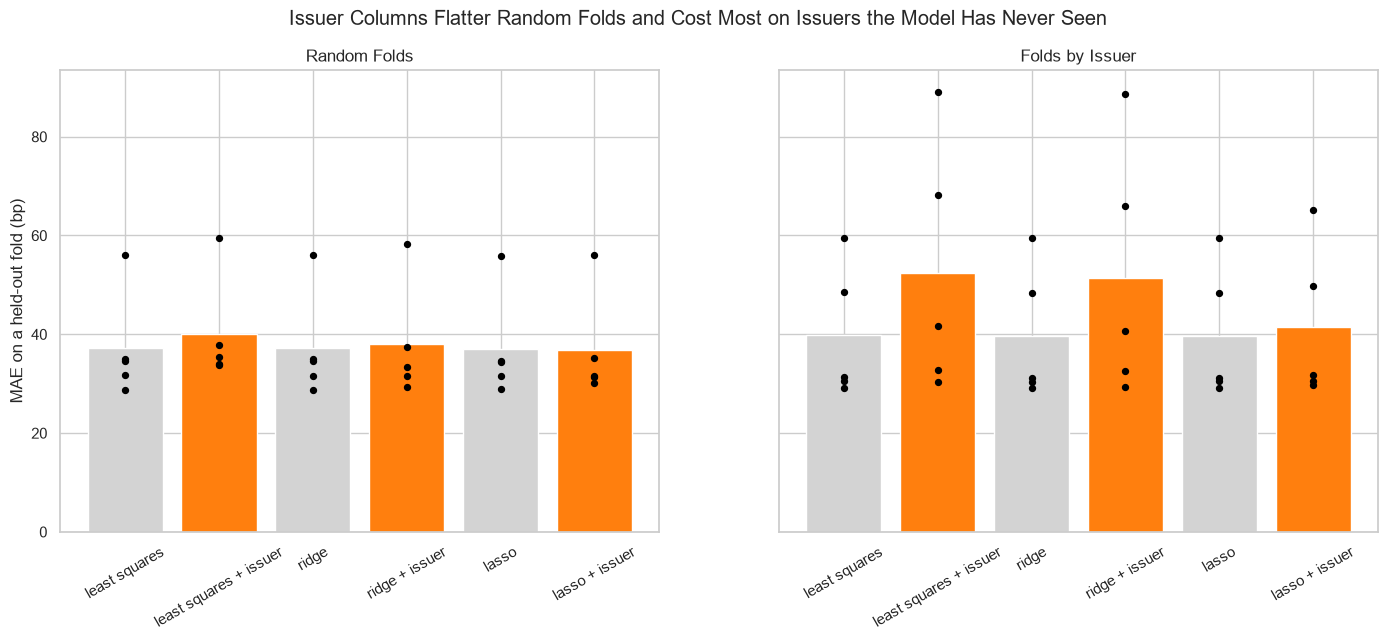

In [42]:
# mean MAE per model as a bar, each fold as a dot: random folds on the left, folds by issuer on the right
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, table, title in [(axes[0], random_mae, "Random Folds"), (axes[1], issuer_mae, "Folds by Issuer")]:
    ax.bar(table.columns, table.mean(), color=["lightgray", "tab:orange"] * 3)
    for name in table.columns:
        ax.scatter([name] * 5, table[name], color="black", s=18, zorder=3)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("MAE on a held-out fold (bp)")
fig.suptitle("Issuer Columns Flatter Random Folds and Cost Most on Issuers the Model Has Never Seen")
plt.show()

Without issuer columns a new issuer costs about 2.6 bp: least squares 37.19 on random folds, 39.77 by issuer.

With them, the best model on random folds, lasso + issuer at 36.85, comes fourth by issuer at 41.43; least squares + issuer misses one fold by 89.1.

Each issuer has one rating, so issuer columns take over part of the rating's work, and a new issuer's bond gets none of it.

**When a column identifies the issuer, score with folds that keep issuers whole.**

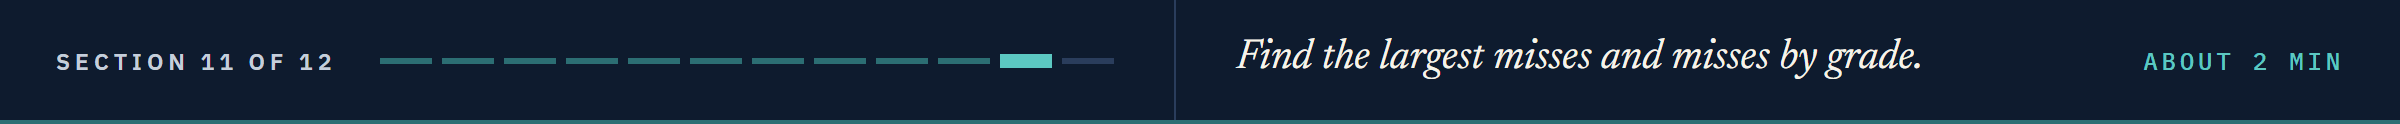

# Where the Model Fails

Back to least squares on the 30 columns and the 206 test bonds.

In [43]:
# each test bond's fitted spread and miss in bp, the miss by grade, and the share within 25 percent of the fitted spread
test_bonds = test[["cusip", "issuer", "rating", "grade", "oas"]].assign(fitted=np.exp(ols_test))
test_bonds["miss"] = (test_bonds["oas"] - test_bonds["fitted"]).abs()
print(test_bonds.groupby("grade")["miss"].mean().round(1))
print("Within 25 percent:", round(((test_bonds["oas"] / test_bonds["fitted"] - 1).abs() <= 0.25).mean(), 3))
print("Five largest misses, share of all the miss:", round(test_bonds["miss"].nlargest(5).sum() / test_bonds["miss"].sum(), 2))
test_bonds.nlargest(5, "miss").round(1)

grade
High Yield         47.000
Investment Grade   18.900
Name: miss, dtype: float64
Within 25 percent: 0.782
Five largest misses, share of all the miss: 0.22


,cusip,issuer,rating,grade,oas,fitted,miss
196,99038MAC3,Praxiskan Finance,CCC+,High Yield,1605,817.700,787.300
199,99038MAF6,Praxiskan Finance,CCC+,High Yield,1004,831.600,172.400
706,99128YAE4,Pleverone Utilities,B,High Yield,383,508.900,125.900
703,99128YAB0,Pleverone Utilities,B,High Yield,285,400.700,115.700
210,99040OAB7,Elvizal Retail,BBB-,Investment Grade,313,200.800,112.200


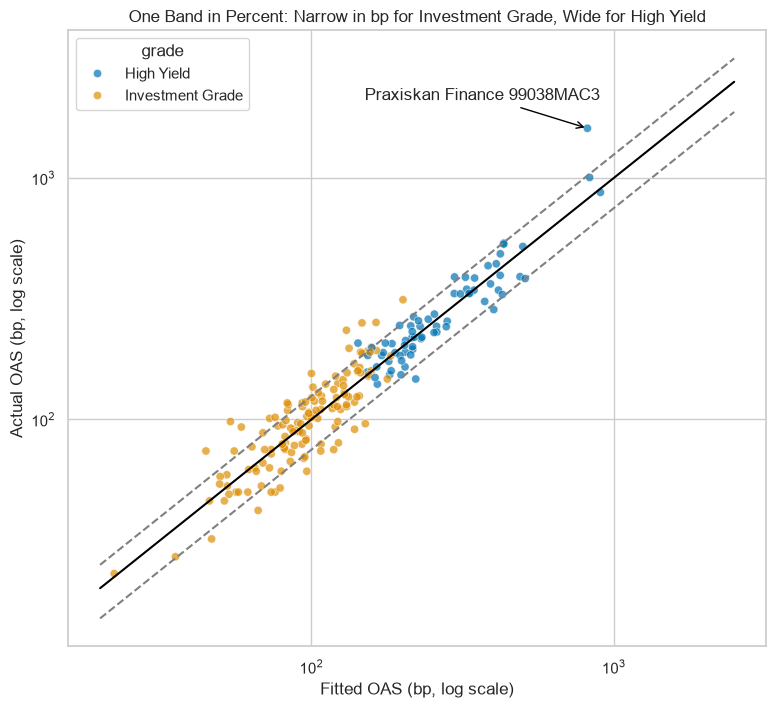

In [44]:
# actual against fitted spread on log axes: the solid line is a perfect fit, the dashed lines 25 percent either side
line = np.array([20, 2500])
plt.figure(figsize=(9, 8))
sns.scatterplot(data=test_bonds, x="fitted", y="oas", hue="grade", alpha=0.7)
plt.plot(line, line, color="black")
plt.plot(line, line * 1.25, color="gray", linestyle="--")
plt.plot(line, line * 0.75, color="gray", linestyle="--")
worst = test_bonds.loc[test_bonds["miss"].idxmax()]
plt.annotate("Praxiskan Finance " + worst["cusip"], (worst["fitted"], worst["oas"]), xytext=(150, 2100),
             arrowprops={"arrowstyle": "->", "color": "black"})
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Fitted OAS (bp, log scale)")
plt.ylabel("Actual OAS (bp, log scale)")
plt.title("One Band in Percent: Narrow in bp for Investment Grade, Wide for High Yield")
plt.show()

78 percent of the test bonds sit within 25 percent of their fitted spread.

That band is 25 bp on a 100 bp bond and 250 bp on a 1,000 bp bond: high yield misses 47.0 bp on average, investment grade 18.9.

Praxiskan Finance `99038MAC3`, CCC+ at 1,605 bp, is still the largest miss, 787.3 bp; the five largest are 22 percent of the total.

A miss is the model's, not a view on any bond.

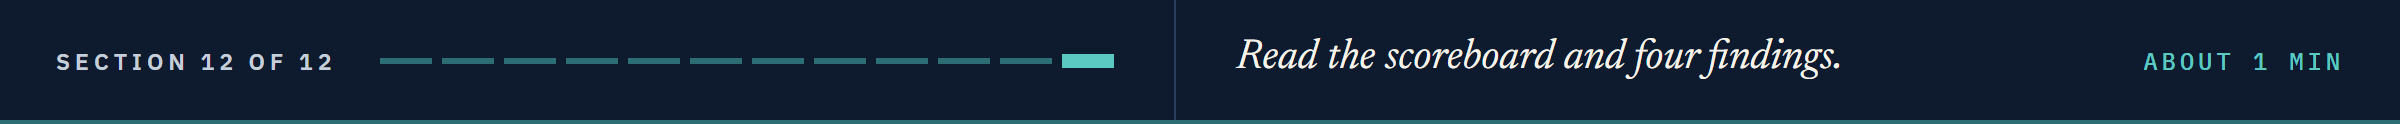

# Insights and Conclusion

In [45]:
# the day's models on bonds they had never seen: the typical miss in bp
pd.Series({"Day 4's model, 18 columns": mae_bp(y_test, day4.predict(day4_X.loc[test.index])),
           "least squares, 30 columns": test_table.loc["least squares", "test MAE"],
           "ridge": test_table.loc["ridge", "test MAE"],
           "lasso": test_table.loc["lasso", "test MAE"],
           "least squares without coupon": mae_bp(y_test, no_coupon.predict(X_test)),
           "least squares, new issuers": mae_bp(issuer_test["log_oas"], new_fitted)})

Day 4's model, 18 columns      33.109
least squares, 30 columns      28.433
ridge                          28.445
lasso                          28.356
least squares without coupon   32.596
least squares, new issuers     46.190
dtype: float64

At 30 columns ridge and lasso tie least squares near 28.4 bp; the fold-to-fold spread dwarfs the difference.

Lasso empties the sectors first, which the recipe never used, but at its chosen alpha keeps 29 of 30 columns.

Coupon improves the score and bends the rating steps away from the recipe.

Issuer columns need a penalty and help only issuers already seen.

**Week 1 ends with a model that describes these bonds and an honest price for a new issuer. Week 2 asks whether a borrower pays.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Build a `Pipeline` with a `ColumnTransformer` that encodes and scales on training rows only.
* Fit ridge and lasso, read a coefficient path, and say what alpha does.
* Choose alpha by cross-validation with `RidgeCV` and `LassoCV`, and spot a choice at a grid's edge.
* Score in bp on every fold with `make_scorer`.
* Split by issuer with `GroupShuffleSplit` and `GroupKFold`.

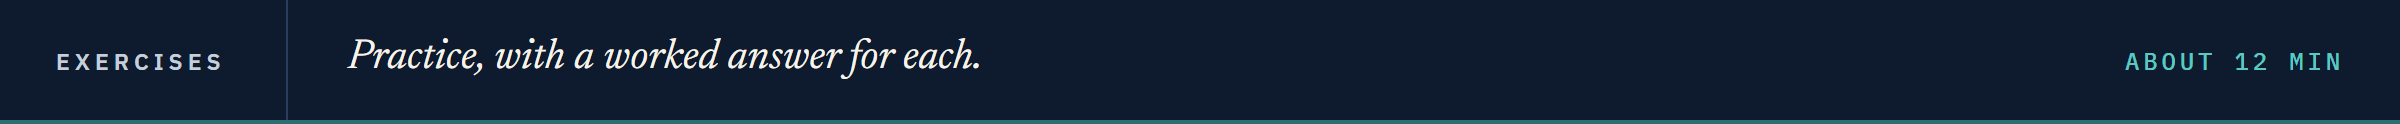

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Elastic Net**

An elastic net charges both penalties at once; `l1_ratio` is lasso's share of the charge, 1 for pure lasso.

Q. Put `ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], alphas=lasso_grid, cv=folds, random_state=SEED)`, imported from `sklearn.linear_model`, into `make_model` and fit it on the training bonds.
Store the chosen `.l1_ratio_` in `ex1_l1_ratio` and the test MAE in bp in `ex1_test_mae_bp`.

In [47]:
# your code here
ex1_l1_ratio = ...
ex1_test_mae_bp = ...

In [48]:
check("Exercise 1 the chosen l1_ratio", ex1_l1_ratio, 0.9)
check("Exercise 1 the test MAE", ex1_test_mae_bp, 28.372049473314714)

Exercise 1 the chosen l1_ratio: not attempted yet
Exercise 1 the test MAE: not attempted yet


### Exercise 2

**Lasso on New Issuers**

Q. Fit `make_model(LassoCV(alphas=lasso_grid, cv=folds, random_state=SEED))` on `issuer_train`.
Store its test MAE in bp on `issuer_test` in `ex2_test_mae_bp`, and the number of its coefficients at exactly zero in `ex2_zeros`.

In [49]:
# your code here
ex2_test_mae_bp = ...
ex2_zeros = ...

In [50]:
check("Exercise 2 the test MAE on new issuers", ex2_test_mae_bp, 46.18312209282846)
check("Exercise 2 the coefficients at zero", ex2_zeros, 0)

Exercise 2 the test MAE on new issuers: not attempted yet
Exercise 2 the coefficients at zero: not attempted yet


### Exercise 3

**The Columns Lasso Dropped**

Q. Write `zeroed(coefs)`: it returns, as a list, the names in a Series of coefficients whose value is exactly zero.
Use it on lasso at alpha 0.002, fitted in `make_model` on the training bonds, and store the list in `ex3_zeroed`.

In [51]:
# your code here
ex3_zeroed = ...

In [52]:
check("Exercise 3 the columns at zero", ex3_zeroed, ["categories__sector_Energy", "categories__sector_Materials", "categories__sector_Technology", "numbers__years_to_maturity"])

Exercise 3 the columns at zero: not attempted yet


### Exercise 4: AI check

**A Fair Penalty**

You asked an AI assistant for ridge on three scaled numbers, scored in bp on the course's test bonds.

This came back.

It runs, and its test MAE looks right.

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def scaled_ridge(bonds, alpha=10):
    # scale the three numbers so the penalty treats them alike, split with the course seed, fit ridge, score in bp
    X = bonds[["score", "duration", "coupon"]]
    scaler = StandardScaler().fit(X)
    X_scaled = pd.DataFrame(scaler.transform(X), index=X.index, columns=X.columns)
    X_fit, X_new, y_fit, y_new = train_test_split(X_scaled, bonds["log_oas"], test_size=0.25, random_state=SEED)
    model = Ridge(alpha=alpha).fit(X_fit, y_fit)
    return scaler, mae_bp(y_new, model.predict(X_new))

ai_scaler, ai_mae = scaled_ridge(data)
print("Test MAE:", round(ai_mae, 2), "bp")

Test MAE: 28.8 bp


Q. How many bonds did the scaler learn its means from? A fitted scaler counts them in `.n_samples_seen_`; store the count as a whole number in `ex4_rows`.
Then fix the function with a pipeline and store the fixed test MAE in bp in `ex4_test_mae_bp`.

In [54]:
# your code here
ex4_rows = ...
ex4_test_mae_bp = ...

In [55]:
check("Exercise 4 the bonds the scaler learned from", ex4_rows, 821)
check("Exercise 4 the fixed test MAE", ex4_test_mae_bp, 28.79769926897168)

Exercise 4 the bonds the scaler learned from: not attempted yet
Exercise 4 the fixed test MAE: not attempted yet


## Congratulations!

You put every column into one pipeline that learns from the training bonds alone.
You watched ridge hand the rating's work to coupon and lasso empty the sectors first.
You let five folds choose each penalty and found the honest answer at 30 columns: a tie.
Then you held back whole issuers and measured what a new name costs.
Week 2 brings a new file and a new question: whether a borrower pays.

[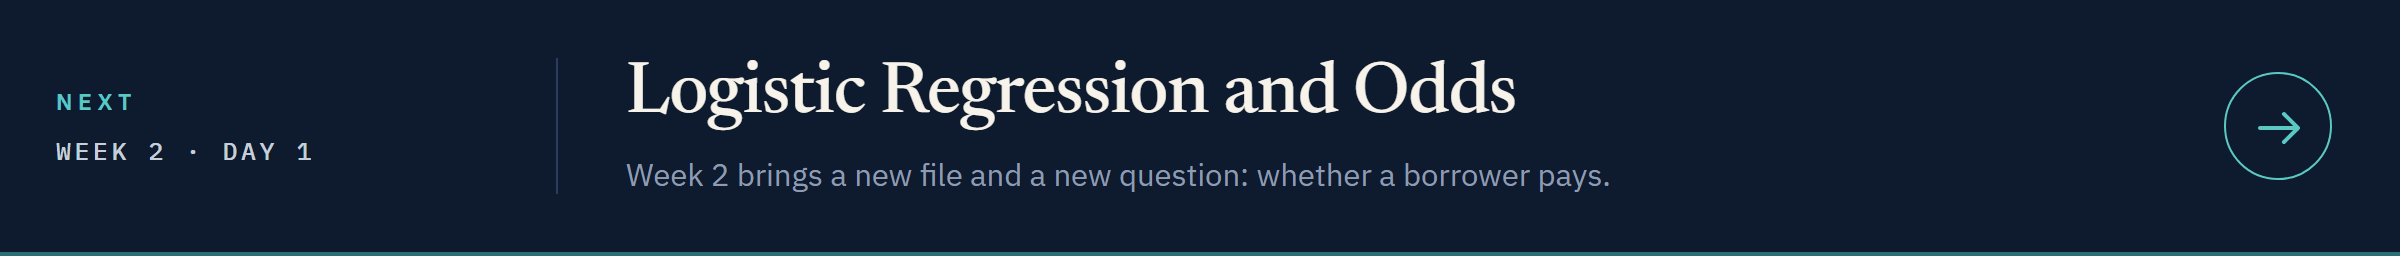](../../week2/day1/06_logistic_regression_and_odds.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day1/06_logistic_regression_and_odds.ipynb)